# Лабораторная работа № 3. Кластеризация Wine Dataset

**Цель работы** — изучить алгоритмы кластеризации, приобрести навыки оценки качества разбиения данных на кластеры и интерпретации результатов.

**Задачи:** выполнить разведочный анализ (размерность, типы признаков, пропуски, распределения и близость к нормальному, информационная значимость признаков, выбросы); обосновать масштабирование; визуально оценить структуру данных; подобрать число кластеров; реализовать K-means и агломеративную иерархическую кластеризацию (Ward); рассчитать внутренние и внешние метрики, расстояния между кластерами, внутрикластерные расстояния, компактность и центры; исследовать влияние параметров; визуализировать результат через PCA и содержательно интерпретировать группы.

Отчёт оформлен в виде ноутбука: все выводы, таблицы и графики воспроизводятся при последовательном выполнении ячеек. Истинные метки `wine.target` **не используются** при обучении, выборе числа кластеров и настройке параметров; они привлекаются только на этапе внешней проверки (раздел 7.2), как это допускает задание.

## 1. Введение

Кластеризация относится к обучению без учителя: алгоритм группирует объекты по сходству признаков, не получая правильных ответов. В работе сравниваются два метода, использующих евклидово расстояние:

* **K-means** — итерационно минимизирует сумму квадратов расстояний объектов до центроидов; хорошо работает для компактных, приблизительно сферических кластеров;
* **агломеративная иерархическая кластеризация с критерием Ward** — последовательно объединяет группы с минимальным приростом внутрикластерной дисперсии; не требует случайной инициализации и позволяет увидеть вложенную структуру.

Wine Dataset содержит 178 образцов, 13 числовых химических признаков и три известных класса (59 / 71 / 48 объектов). Наличие классов делает возможной внешнюю проверку, но не отменяет постановку задачи кластеризации: структура ищется только по признакам, а метки используются для последующей интерпретации качества.

## 2. Описание датасета

Загрузим Wine Dataset из `sklearn.datasets`. Матрица признаков содержит 13 количественных переменных (крепость, кислотность, фенолы, интенсивность окраски, пролин и др.). Пропусков нет. Метки классов хранятся отдельно от матрицы признаков.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
    rand_score, adjusted_rand_score, normalized_mutual_info_score, adjusted_mutual_info_score,
    fowlkes_mallows_score, homogeneity_completeness_v_measure,
    jaccard_score, confusion_matrix, pairwise_distances
)
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.covariance import MinCovDet
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import pdist
from scipy.stats import shapiro, f_oneway, kruskal, skew, kurtosis, probplot, chi2

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target

print(f"Размерность матрицы признаков: {X.shape}")
print(f"Число объектов: {X.shape[0]}, число признаков: {X.shape[1]}")
print("\nТипы признаков:")
print(X.dtypes)
print(f"\nСуммарное число пропусков: {int(X.isna().sum().sum())}")
print("\nРаспределение известных классов (используется только для внешней проверки):")
print(pd.Series(y_true).value_counts().sort_index().to_string())
print("\nПервые пять строк:")
display(X.head())

Размерность матрицы признаков: (178, 13)
Число объектов: 178, число признаков: 13

Типы признаков:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
dtype: object

Суммарное число пропусков: 0

Распределение известных классов (используется только для внешней проверки):
0    59
1    71
2    48

Первые пять строк:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### 2.1. Распределения признаков и проверка нормальности

Построим гистограммы **всех 13** признаков и дополним их формальной проверкой: критерием Шапиро–Уилка (H0 — выборка из нормального распределения), асимметрией, эксцессом и квантиль-квантильными графиками для наиболее отклоняющихся переменных.

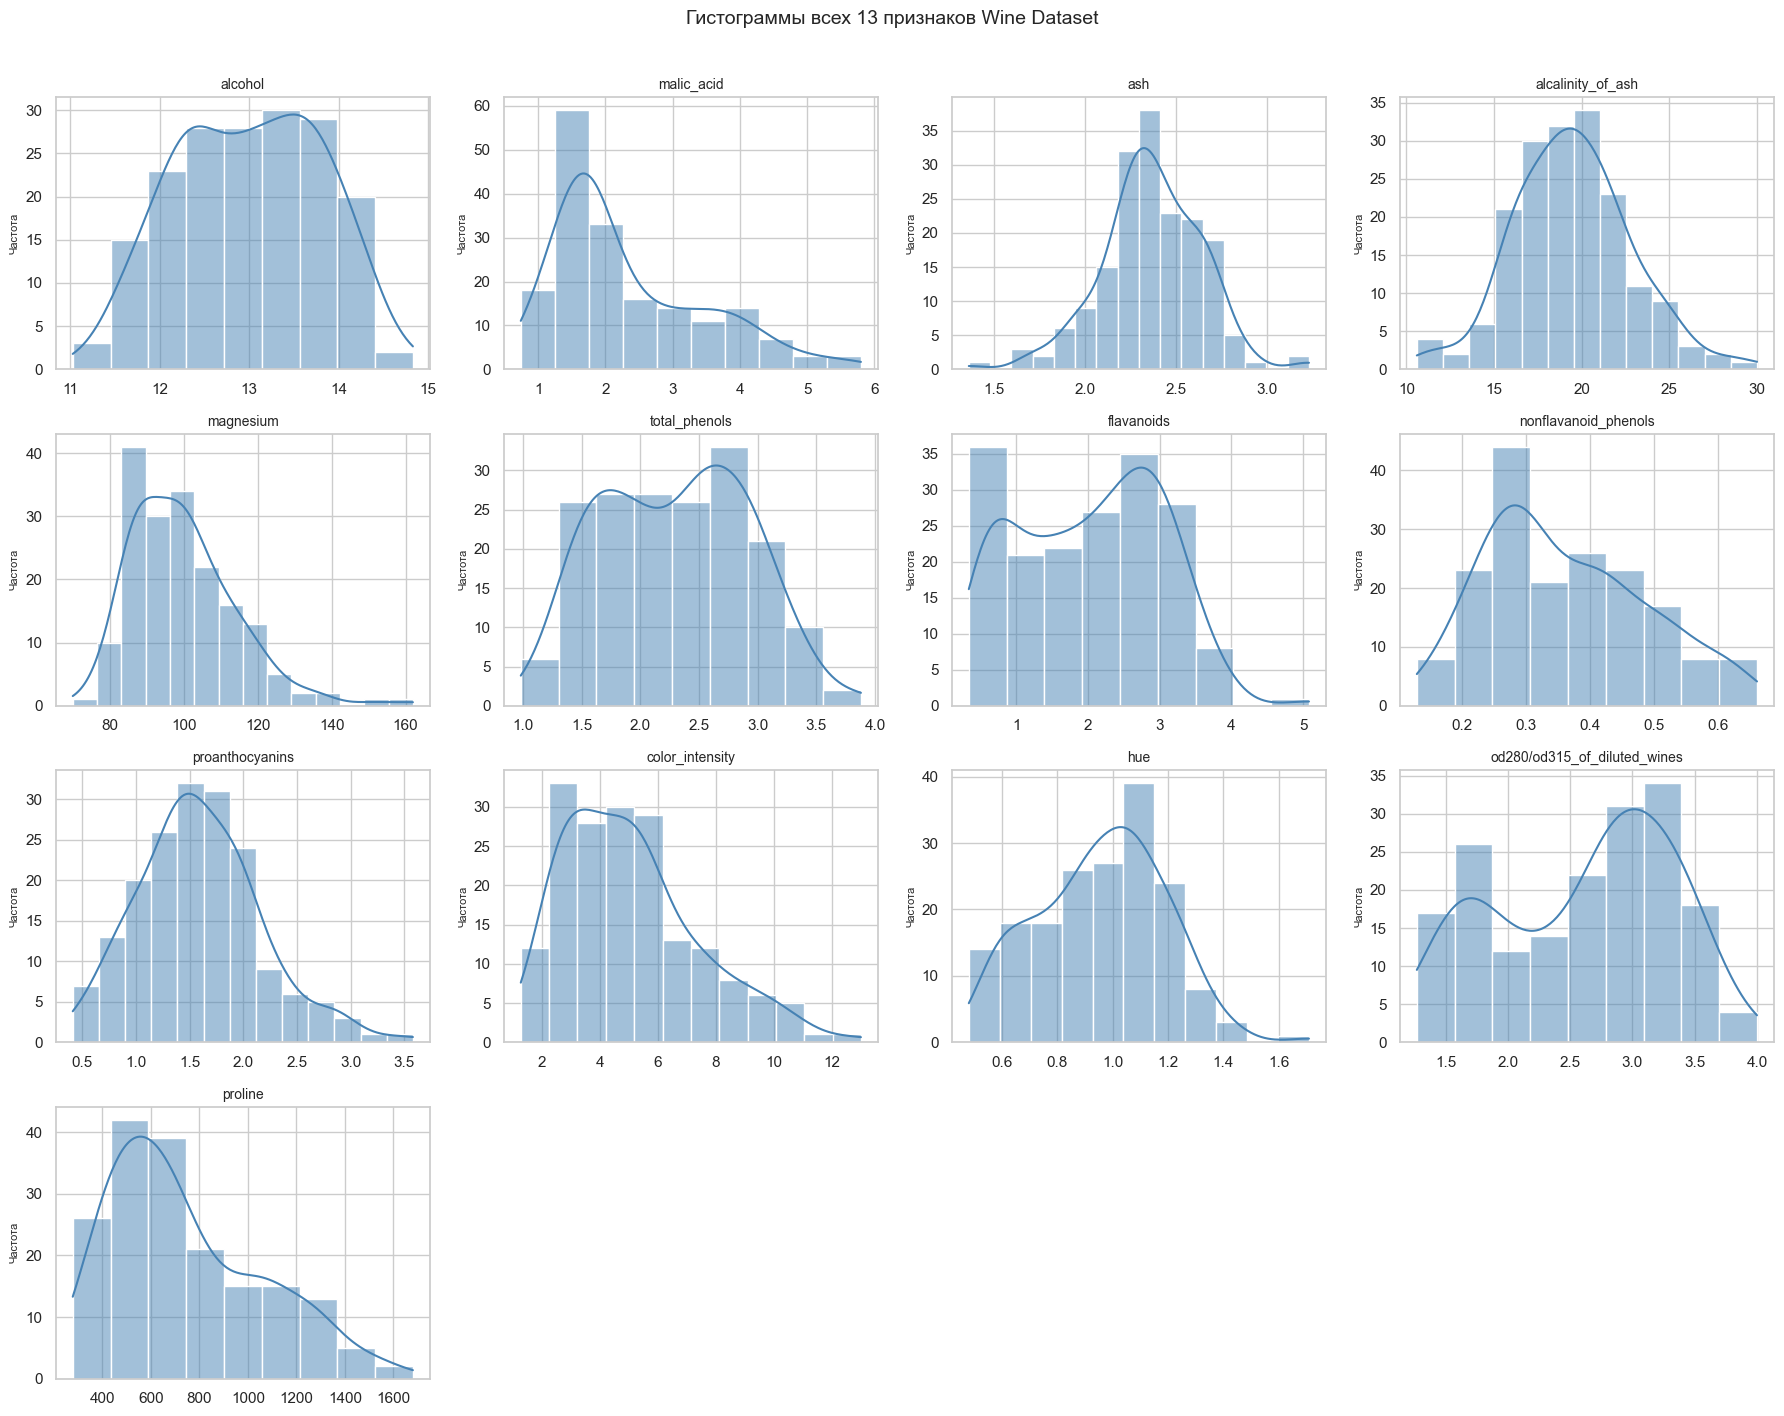

,W,p-value,Асимметрия,Эксцесс,Вывод (α = 0.05)
alcohol,0.9818,0.0200,-0.0510,-0.8623,нормальность отвергается
malic_acid,0.8888,0.0000,1.0309,0.2573,нормальность отвергается
ash,0.9839,0.0387,-0.1752,1.0786,нормальность отвергается
alcalinity_of_ash,0.9902,0.2639,0.2112,0.4408,нет оснований отвергнуть
magnesium,0.9383,0.0000,1.0889,2.0128,нормальность отвергается
total_phenols,0.9767,0.0044,0.0859,-0.8459,нормальность отвергается
flavanoids,0.9545,0.0000,0.0251,-0.8894,нормальность отвергается
nonflavanoid_phenols,0.9625,0.0001,0.4463,-0.6530,нормальность отвергается
proanthocyanins,0.9807,0.0145,0.5128,0.5057,нормальность отвергается
color_intensity,0.9403,0.0000,0.8612,0.3374,нормальность отвергается


Нормальность отвергается для 12 из 13 признаков.
Наиболее сильные отклонения (наименьшие W):
                                   W  p-value  Асимметрия  Эксцесс
malic_acid                    0.8888      0.0      1.0309   0.2573
proline                       0.9312      0.0      0.7613  -0.2750
magnesium                     0.9383      0.0      1.0889   2.0128
color_intensity               0.9403      0.0      0.8612   0.3374
od280/od315_of_diluted_wines  0.9450      0.0     -0.3047  -1.0897
flavanoids                    0.9545      0.0      0.0251  -0.8894


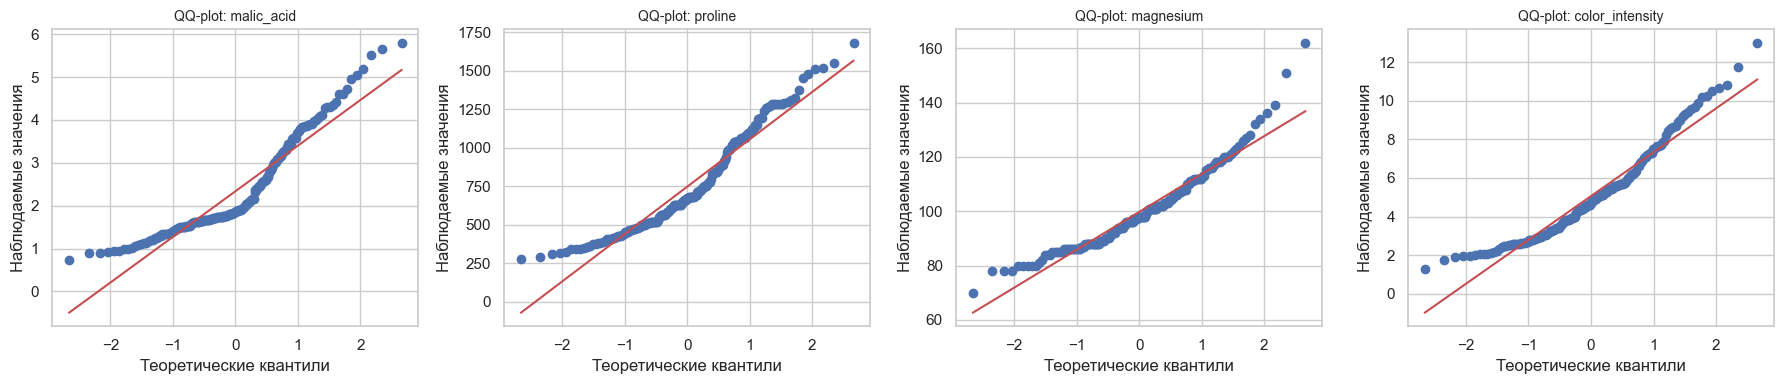

Вывод: 12 из 13 признаков статистически значимо отличаются от нормального распределения;
наиболее асимметричны malic_acid (1.03), magnesium (1.09), color_intensity (0.86) и proline (0.76).
K-means не требует нормальности (минимизируется сумма квадратов, а не функция правдоподобия),
однако ненормальность и тяжёлые хвосты означают, что: (а) значимость признаков нужно дублировать
непараметрическим критерием Краскела–Уоллиса; (б) устойчивость разбиения следует проверить бутстрэпом.


In [2]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, feature in zip(axes.flat, X.columns):
    sns.histplot(X[feature], kde=True, ax=ax, color="steelblue", edgecolor="white")
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Частота", fontsize=8)
for ax in axes.flat[len(X.columns):]:
    ax.axis("off")
plt.suptitle("Гистограммы всех 13 признаков Wine Dataset", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

sw = pd.DataFrame({
    "W": [shapiro(X[c]).statistic for c in X.columns],
    "p-value": [shapiro(X[c]).pvalue for c in X.columns],
    "Асимметрия": [skew(X[c]) for c in X.columns],
    "Эксцесс": [kurtosis(X[c]) for c in X.columns],
}, index=X.columns)
sw["Вывод (α = 0.05)"] = np.where(sw["p-value"] < 0.05, "нормальность отвергается", "нет оснований отвергнуть")
display(sw.round(4))

print(f"Нормальность отвергается для {int((sw['p-value'] < 0.05).sum())} из {len(sw)} признаков.")
print("Наиболее сильные отклонения (наименьшие W):")
print(sw.sort_values("W").head(6)[["W", "p-value", "Асимметрия", "Эксцесс"]].round(4).to_string())

qq_features = sw.sort_values("W").head(4).index
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, feature in zip(axes, qq_features):
    probplot(X[feature], dist="norm", plot=ax)
    ax.set_title(f"QQ-plot: {feature}", fontsize=10)
    ax.set_xlabel("Теоретические квантили")
    ax.set_ylabel("Наблюдаемые значения")
plt.tight_layout()
plt.show()

print("Вывод: 12 из 13 признаков статистически значимо отличаются от нормального распределения;")
print("наиболее асимметричны malic_acid (1.03), magnesium (1.09), color_intensity (0.86) и proline (0.76).")
print("K-means не требует нормальности (минимизируется сумма квадратов, а не функция правдоподобия),")
print("однако ненормальность и тяжёлые хвосты означают, что: (а) значимость признаков нужно дублировать")
print("непараметрическим критерием Краскела–Уоллиса; (б) устойчивость разбиения следует проверить бутстрэпом.")

### 2.2. Анализ выбросов

Проверим **все 13 признаков** правилом 1.5 IQR: границы `Q1 − 1.5·IQR` и `Q3 + 1.5·IQR`, а также число флагов у каждого объекта. Дополнительно оценим многомерную картину робастным расстоянием Махаланобиса.

Выбросы не удаляются автоматически: экстремальные значения могут быть реальными характеристиками вин (креплёные вина, высокое содержание пролина). Важно, что **стандартизация не ослабляет влияние выбросов** — она лишь приводит признаки к единому масштабу, поэтому устойчивость результата проверяется отдельно (бутстрэп в разделе 5.2).

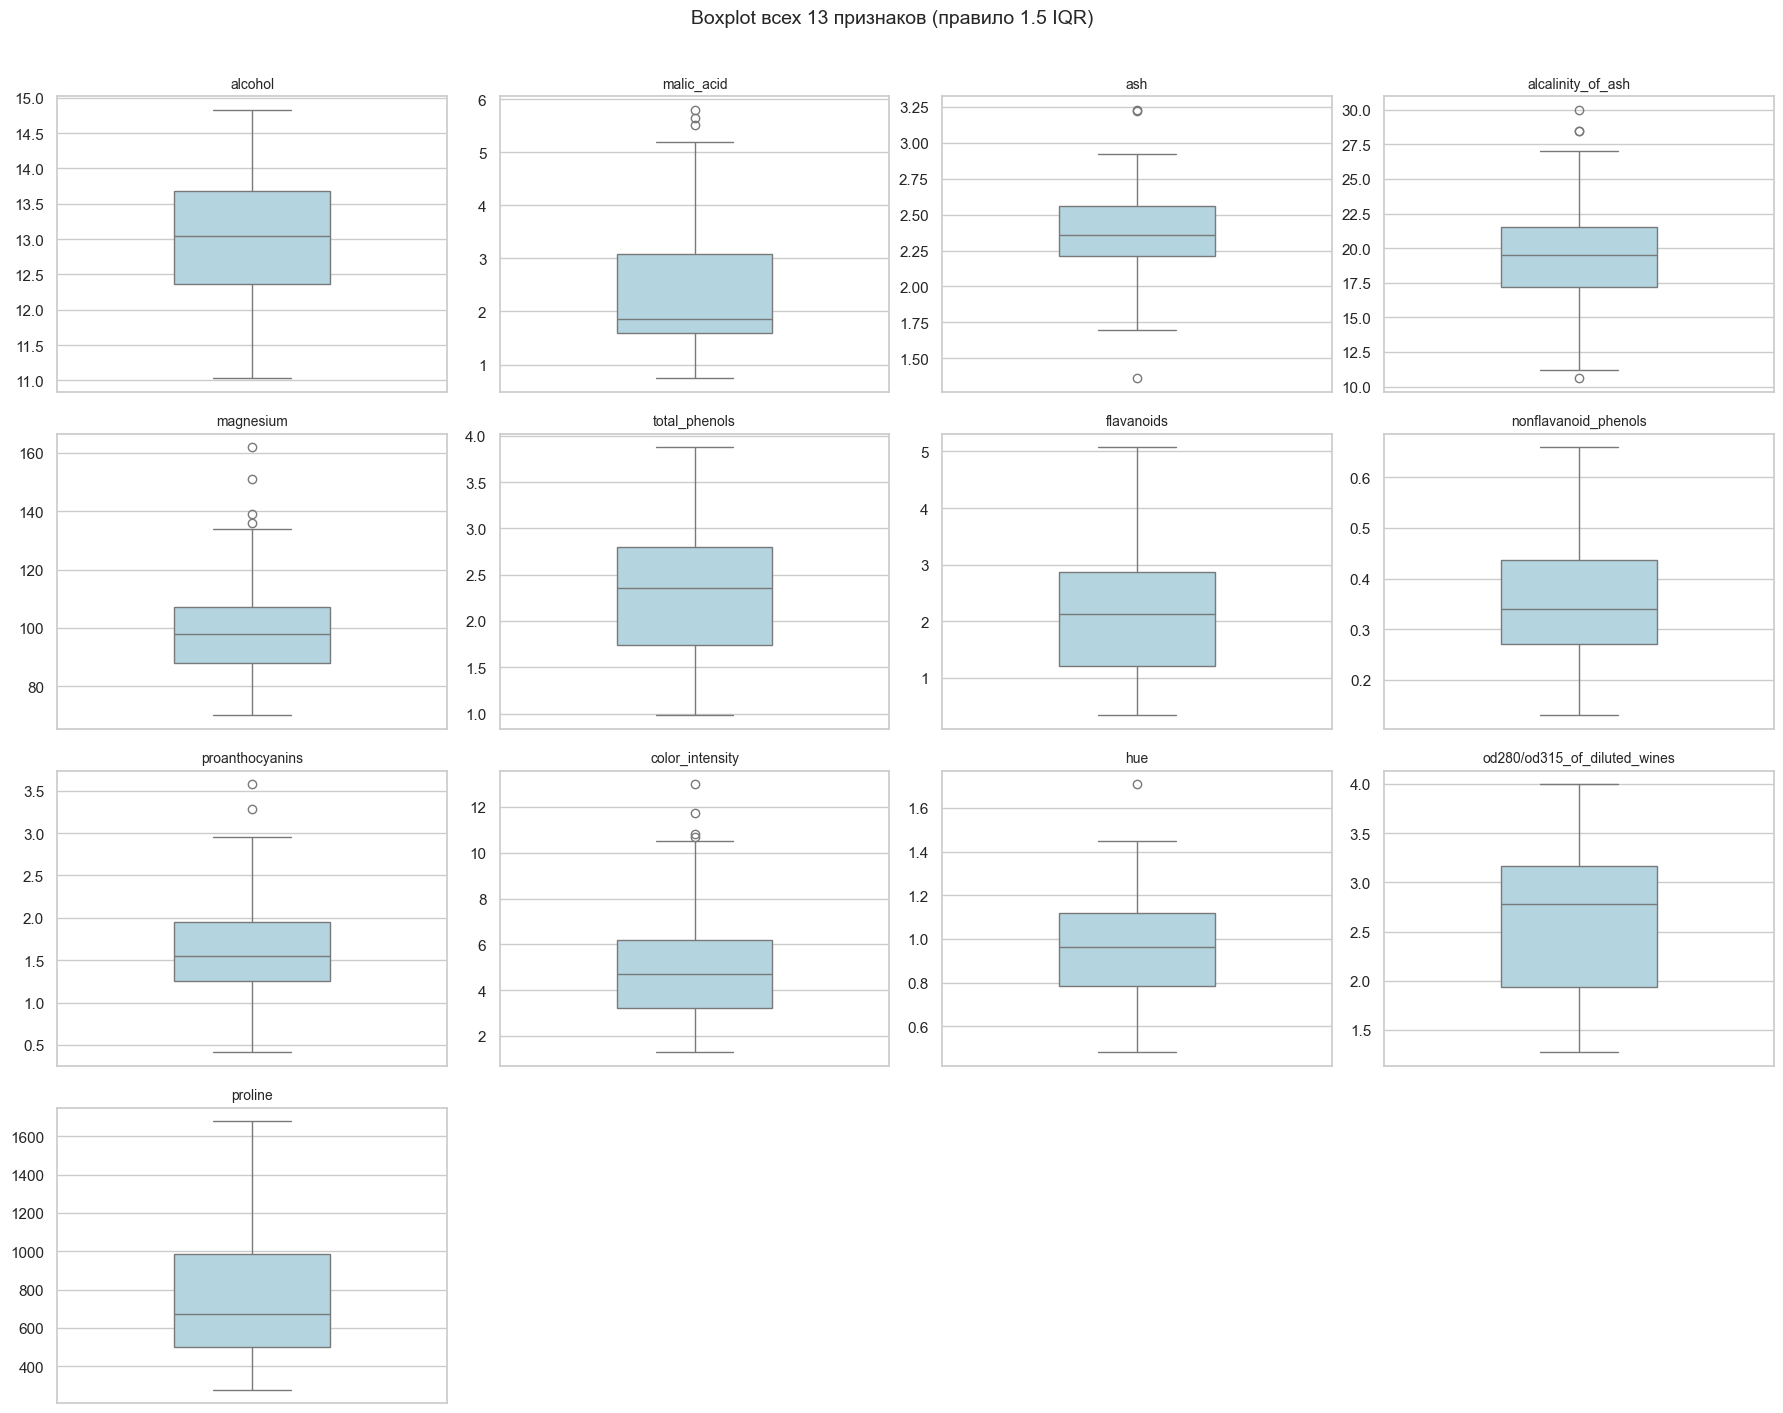

,Нижняя граница,Верхняя граница,"Выбросов, шт.","Доля, %"
alcohol,10.39,15.65,0,0.0
malic_acid,-0.62,5.30,3,1.7
ash,1.69,3.08,3,1.7
alcalinity_of_ash,10.75,27.95,4,2.2
magnesium,59.50,135.50,4,2.2
total_phenols,0.16,4.39,0,0.0
flavanoids,-1.30,5.38,0,0.0
nonflavanoid_phenols,0.02,0.69,0,0.0
proanthocyanins,0.20,3.00,2,1.1
color_intensity,-1.25,10.67,4,2.2


Распределение числа флагов по объектам:
Всего флагов
0    161
1     13
2      4
Объектов хотя бы с одним флагом: 17 из 178
Объектов с двумя и более флагами: 4
Объекты с двумя флагами: [59, 73, 95, 121]

Глобальный робастный Махаланобис: 51 объектов выше порога chi2(0.975, 13) = 24.74.
Высокая доля объясняется многомодальностью данных (три группы), а не аномальностями,
поэтому для удаления объектов эта проверка не используется; она лишь подтверждает,
что одномерные IQR-флаги (17 объектов, из них 4 — с двумя флагами) отражают реальные крайние значения.


In [3]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, feature in zip(axes.flat, X.columns):
    sns.boxplot(y=X[feature], ax=ax, color="lightblue", width=0.4)
    ax.set_title(feature, fontsize=10)
    ax.set_ylabel("")
for ax in axes.flat[len(X.columns):]:
    ax.axis("off")
plt.suptitle("Boxplot всех 13 признаков (правило 1.5 IQR)", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

flags = pd.DataFrame(index=X.index)
bounds = {}
for c in X.columns:
    q1, q3 = X[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    flags[c] = (X[c] < q1 - 1.5 * iqr) | (X[c] > q3 + 1.5 * iqr)
    bounds[c] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)

outliers = pd.DataFrame({
    "Нижняя граница": {c: round(bounds[c][0], 2) for c in X.columns},
    "Верхняя граница": {c: round(bounds[c][1], 2) for c in X.columns},
    "Выбросов, шт.": flags.sum(),
    "Доля, %": (flags.mean() * 100).round(1),
})
display(outliers)

flags["Всего флагов"] = flags.sum(axis=1)
print("Распределение числа флагов по объектам:")
print(flags["Всего флагов"].value_counts().sort_index().to_string())
print(f"Объектов хотя бы с одним флагом: {int((flags['Всего флагов'] >= 1).sum())} из {len(X)}")
print(f"Объектов с двумя и более флагами: {int((flags['Всего флагов'] >= 2).sum())}")
print("Объекты с двумя флагами:", flags.index[flags["Всего флагов"] >= 2].tolist())

mcd = MinCovDet(random_state=RANDOM_STATE).fit(X)
md_dist = mcd.mahalanobis(X)
thr = chi2.ppf(0.975, df=X.shape[1])
print(f"\nГлобальный робастный Махаланобис: {int((md_dist > thr).sum())} объектов выше порога chi2(0.975, 13) = {thr:.2f}.")
print("Высокая доля объясняется многомодальностью данных (три группы), а не аномальностями,")
print("поэтому для удаления объектов эта проверка не используется; она лишь подтверждает,")
print("что одномерные IQR-флаги (17 объектов, из них 4 — с двумя флагами) отражают реальные крайние значения.")

### 2.3. Корреляционный анализ: избыточность признаков

Матрица корреляций Пирсона показывает **линейное дублирование информации** между признаками, а не их значимость для классов. Сильно коррелирующие пары увеличивают вес соответствующего направления в евклидовом расстоянии, поэтому их полезно знать.

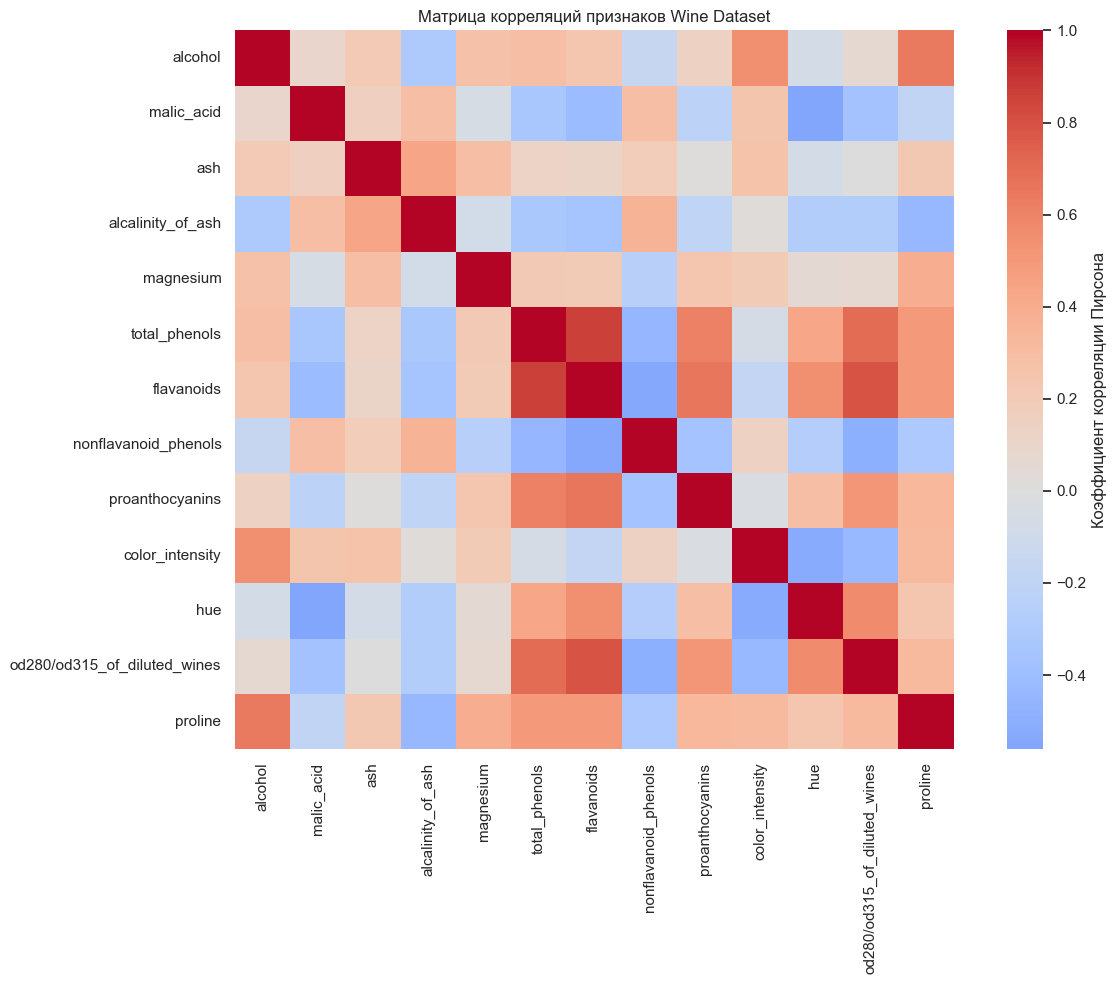

Пары признаков с |корреляцией| >= 0.75:


,,Корреляция
total_phenols,flavanoids,0.865
flavanoids,od280/od315_of_diluted_wines,0.787


Сильно коррелирующие пары несут частично общую информацию. Признаки не удаляются,
чтобы сохранить интерпретируемость, но при чтении центров кластеров это дублирование учитывается.


In [4]:
corr = X.corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True,
            cbar_kws={"label": "Коэффициент корреляции Пирсона"})
plt.title("Матрица корреляций признаков Wine Dataset")
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong_pairs = (
    upper.stack()
    .loc[lambda s: s.abs() >= 0.75]
    .sort_values(key=np.abs, ascending=False)
)
print("Пары признаков с |корреляцией| >= 0.75:")
display(strong_pairs.rename("Корреляция").to_frame().round(3))
print("Сильно коррелирующие пары несут частично общую информацию. Признаки не удаляются,")
print("чтобы сохранить интерпретируемость, но при чтении центров кластеров это дублирование учитывается.")

### 2.4. Информационная значимость признаков

Корреляции характеризуют избыточность, а не связь с классами. Оценим значимость каждого признака тремя способами:

1. **ANOVA F-статистика** (и размер эффекта η²) — проверяет различие средних между тремя классами;
2. **критерий Краскела–Уоллиса H** — непараметрический аналог, не требующий нормальности (которая, как показано в 2.1, в основном отвергается);
3. **взаимная информация (mutual information)** — улавливает в том числе нелинейные зависимости.

Метки классов используются **только для интерпретации данных**; признаковый отбор по этим метрикам не проводится, кластеризация выполняется по всем 13 признакам.

,F (ANOVA),p (ANOVA),η²,H (Краскел–Уоллис),p (Краскел),Mutual information
Признак,,,,,,
flavanoids,233.9259,0.0,0.7278,130.4524,0.0,0.6676
proline,207.9204,0.0,0.7038,119.0598,0.0,0.5774
od280/od315_of_diluted_wines,189.9723,0.0,0.6847,107.0461,0.0,0.5162
alcohol,135.0776,0.0,0.6069,109.5104,0.0,0.4743
color_intensity,120.6640,0.0,0.5797,115.0498,0.0,0.5483
hue,101.3168,0.0,0.5366,92.4375,0.0,0.4664
total_phenols,93.7330,0.0,0.5172,93.4775,0.0,0.4016
malic_acid,36.9434,0.0,0.2969,50.0449,0.0,0.2824
alcalinity_of_ash,35.7716,0.0,0.2902,59.9901,0.0,0.2378


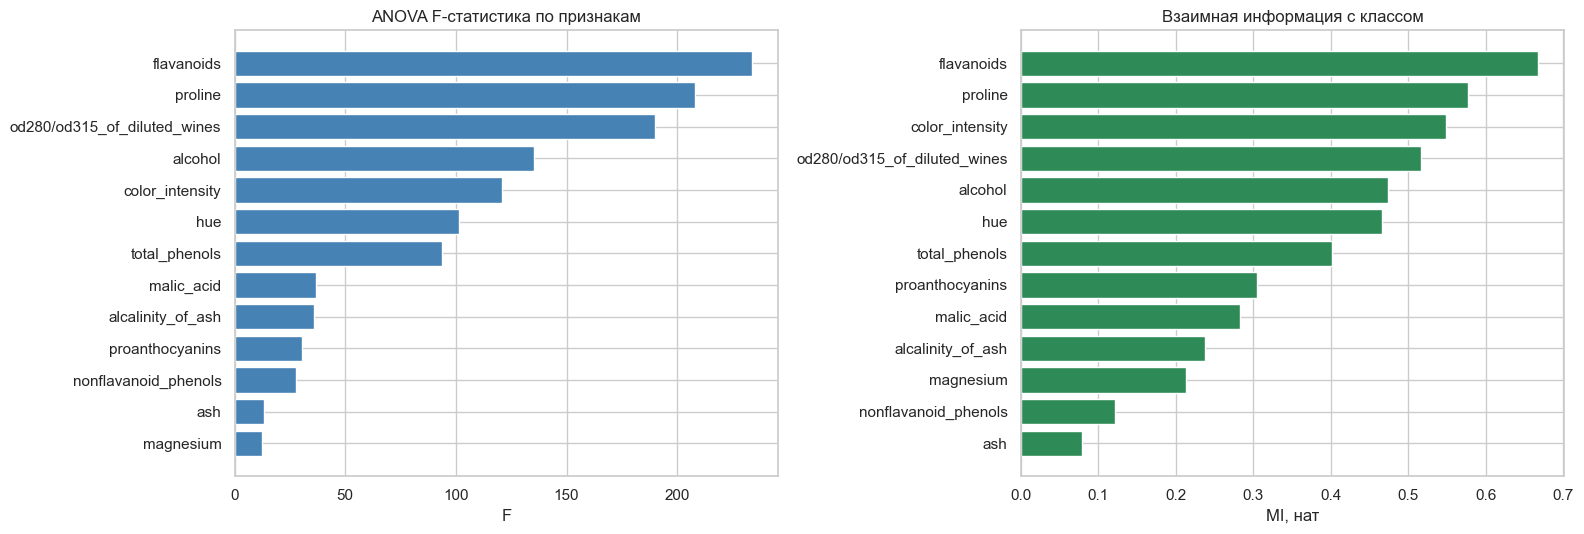

Топ-5 по ANOVA F: flavanoids, proline, od280/od315_of_diluted_wines, alcohol, color_intensity
Топ-5 по mutual information: flavanoids, proline, color_intensity, od280/od315_of_diluted_wines, alcohol
Слабейшие по ANOVA F: magnesium, ash, nonflavanoid_phenols
Все p-value ANOVA и Краскела–Уоллиса меньше 0.001: связь признаков с классами статистически значима.
Признак magnesium имеет низкий F (12.4), но заметную взаимную информацию (0.213):
связь с классом нелинейна, поэтому опираться только на F нельзя.


In [5]:
n_obs, n_cls = len(X), len(np.unique(y_true))
mi = mutual_info_classif(X, y_true, random_state=RANDOM_STATE)
rows = []
for c in X.columns:
    F, p_anova = f_oneway(*[X[c][y_true == cl] for cl in np.unique(y_true)])
    H, p_kw = kruskal(*[X[c][y_true == cl] for cl in np.unique(y_true)])
    eta2 = (n_cls - 1) * F / ((n_cls - 1) * F + (n_obs - n_cls))
    rows.append({"Признак": c, "F (ANOVA)": F, "p (ANOVA)": p_anova, "η²": eta2,
                 "H (Краскел–Уоллис)": H, "p (Краскел)": p_kw,
                 "Mutual information": mi[list(X.columns).index(c)]})

importance = pd.DataFrame(rows).set_index("Признак").sort_values("F (ANOVA)", ascending=False)
display(importance.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
imp_f = importance.sort_values("F (ANOVA)")
axes[0].barh(imp_f.index, imp_f["F (ANOVA)"], color="steelblue")
axes[0].set_title("ANOVA F-статистика по признакам")
axes[0].set_xlabel("F")
imp_mi = importance.sort_values("Mutual information")
axes[1].barh(imp_mi.index, imp_mi["Mutual information"], color="seagreen")
axes[1].set_title("Взаимная информация с классом")
axes[1].set_xlabel("MI, нат")
plt.tight_layout()
plt.show()

print("Топ-5 по ANOVA F:", ", ".join(importance.head(5).index))
print("Топ-5 по mutual information:", ", ".join(importance.sort_values("Mutual information", ascending=False).head(5).index))
print("Слабейшие по ANOVA F:", ", ".join(importance.sort_values("F (ANOVA)").head(3).index))
print("Все p-value ANOVA и Краскела–Уоллиса меньше 0.001: связь признаков с классами статистически значима.")
print("Признак magnesium имеет низкий F (12.4), но заметную взаимную информацию (0.213):")
print("связь с классом нелинейна, поэтому опираться только на F нельзя.")

### 2.5. Применимость кластеризации

Признаки числовые, пропусков нет, масштаб различается на порядки, что требует стандартизации. Формально условие «отсутствие классов» не выполнено (датасет классификационный), однако это не мешает кластеризации: структура ищется только по 13 признакам, а метки используются исключительно для внешней проверки, что прямо предусмотрено заданием. Осмысленность кластеризации подтверждается химической природой признаков и наличием трёх устойчивых профилей (раздел 9). Выбросы сохранены, их влияние проверяется через устойчивость решения.

## 3. Предобработка данных

Применим `StandardScaler`: каждый признак центрируется (среднее 0) и масштабируется на стандартное отклонение (дисперсия 1). Это обосновано тем, что K-means и Ward используют евклидово расстояние, а признаки измеряются в разных единицах и имеют разные диапазоны (пролин — сотни, фенолы — единицы). Без масштабирования пролин и магний доминировали бы в расстоянии.

`StandardScaler` предпочтён `MinMaxScaler`, так как он сохраняет форму распределения и не сжимает основную массу данных из-за экстремальных значений; `RobustScaler` был бы альтернативой при сильных выбросах, но медианное масштабирование исказило бы вклад признаков с естественной асимметрией. Устойчивость выводов к выбору масштабирования кратко проверена в разделе 8.

Стандартизация **не устраняет выбросы** и не делает распределения нормальными — она только выравнивает масштаб.

In [6]:
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns, index=X.index)

print("Средние после стандартизации (должны быть близки к 0):")
print(X_scaled.mean().round(3).to_string())
print("\nСтандартные отклонения (должны быть близки к 1):")
print(X_scaled.std(ddof=0).round(3).to_string())
display(X_scaled.head())

Средние после стандартизации (должны быть близки к 0):
alcohol                        -0.0
malic_acid                     -0.0
ash                            -0.0
alcalinity_of_ash              -0.0
magnesium                      -0.0
total_phenols                   0.0
flavanoids                     -0.0
nonflavanoid_phenols            0.0
proanthocyanins                -0.0
color_intensity                 0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                        -0.0

Стандартные отклонения (должны быть близки к 1):
alcohol                         1.0
malic_acid                      1.0
ash                             1.0
alcalinity_of_ash               1.0
magnesium                       1.0
total_phenols                   1.0
flavanoids                      1.0
nonflavanoid_phenols            1.0
proanthocyanins                 1.0
color_intensity                 1.0
hue                             1.0
od280/od315_of_diluted_wines   

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


## 4. Визуальная оценка структуры данных

Построим матрицу диаграмм рассеивания по четырём наиболее информативным признакам **без раскраски по классам**, чтобы оценить структуру только по данным: наличие изолированных сгущений, перекрытие, вытянутость и предполагаемое число групп.

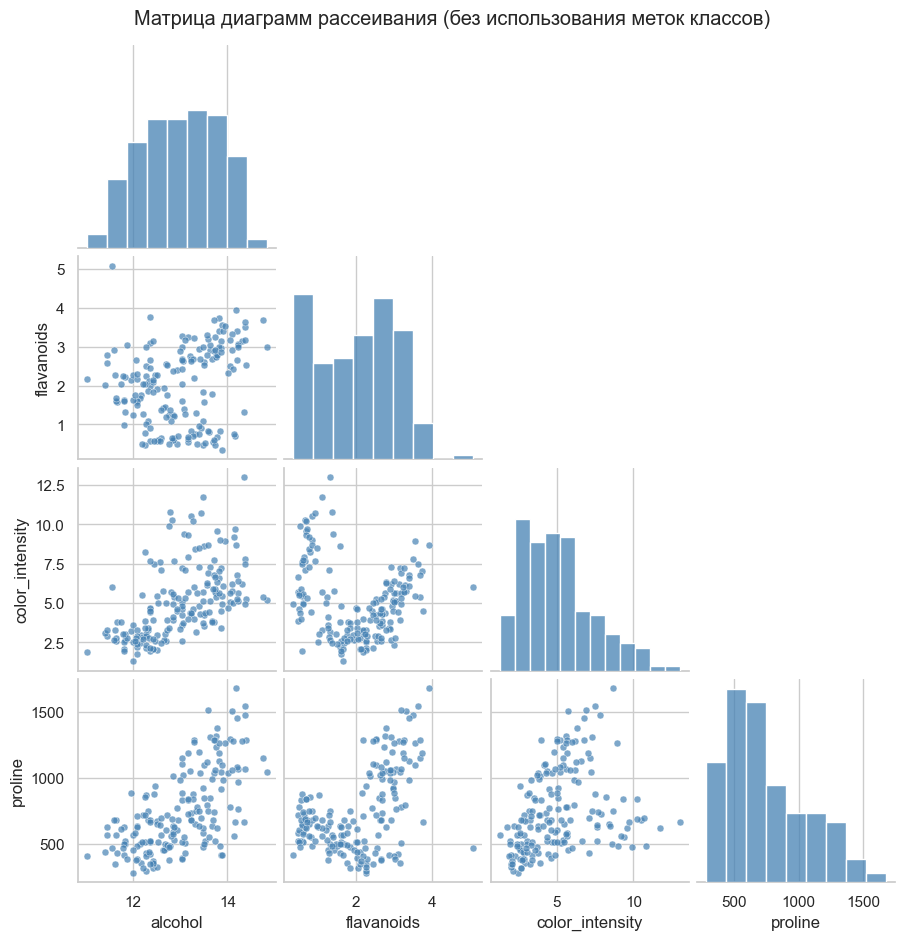

На проекциях видны области повышенной плотности и частичное перекрытие;
явно изолированных групп нет, структура скорее вытянутая/цепочкообразная.
Поэтому проверяем k = 2–4 и опираемся не только на геометрию, но и на устойчивость разбиения.


In [7]:
pair_features = ["alcohol", "flavanoids", "color_intensity", "proline"]
sns.pairplot(X[pair_features], vars=pair_features, diag_kind="hist", corner=True, height=2.3,
             plot_kws={"s": 25, "alpha": 0.7, "color": "steelblue"},
             diag_kws={"color": "steelblue"})
plt.suptitle("Матрица диаграмм рассеивания (без использования меток классов)", y=1.02)
plt.show()

print("На проекциях видны области повышенной плотности и частичное перекрытие;")
print("явно изолированных групп нет, структура скорее вытянутая/цепочкообразная.")
print("Поэтому проверяем k = 2–4 и опираемся не только на геометрию, но и на устойчивость разбиения.")

### 4.1. Выбор методов кластеризации

Оба выбранных метода предполагают компактные кластеры и используют евклидово расстояние, что соответствует наблюдаемой структуре (сгущения без выраженной нелинейной формы). K-means удобен интерпретируемыми центроидами и устойчив при `n_init=10`. Ward не требует случайной инициализации, даёт дендрограмму и позволяет оценить иерархию объединений. DBSCAN не выбран, поскольку данные не образуют плотностных кластеров с чёткой границей и имеют близкие по плотности области; GaussianMixture был бы альтернативой, но при 13 признаках и 178 объектах ковариационные оценки менее устойчивы. Ward используется как второй метод для проверки согласованности структуры.

## 5. Подбор оптимального числа кластеров

### 5.1. Метод локтя и внутренние критерии

Рассчитаем inertia (сумму квадратов расстояний до центроидов), silhouette, Calinski–Harabasz и Davies–Bouldin для `k` от 1 до 10. Дополнительно вычислим относительное падение inertia и формальную эвристику локтя — максимальное расстояние точки кривой до хорды, соединяющей её концы.

,k,Inertia,Silhouette,Calinski–Harabasz,Davies–Bouldin,Δ inertia,"Δ, %"
0,1,2314.0000,NaN,NaN,NaN,NaN,NaN
1,2,1658.7589,0.2593,69.5233,1.5260,-655.2,-28.3
2,3,1277.9285,0.2849,70.9400,1.3892,-380.8,-23.0
3,4,1175.4283,0.2602,56.1814,1.7969,-102.5,-8.0
4,5,1109.5127,0.2016,46.9522,1.8083,-65.9,-5.6
5,6,1046.0023,0.2372,41.7008,1.5544,-63.5,-5.7
6,7,981.5952,0.2036,38.6855,1.6606,-64.4,-6.2
7,8,935.2012,0.1570,35.8053,1.7409,-46.4,-4.7
8,9,889.8929,0.1499,33.8066,1.7083,-45.3,-4.8
9,10,845.8952,0.1436,32.3972,1.7070,-44.0,-4.9


Расстояние до хорды (эвристика локтя):
2     0.00
3     2.75
4     2.76
5     2.41
6     2.03
7     1.66
8     1.12
9     0.57
10    0.00
Максимум эвристики локтя приходится на k = 4.


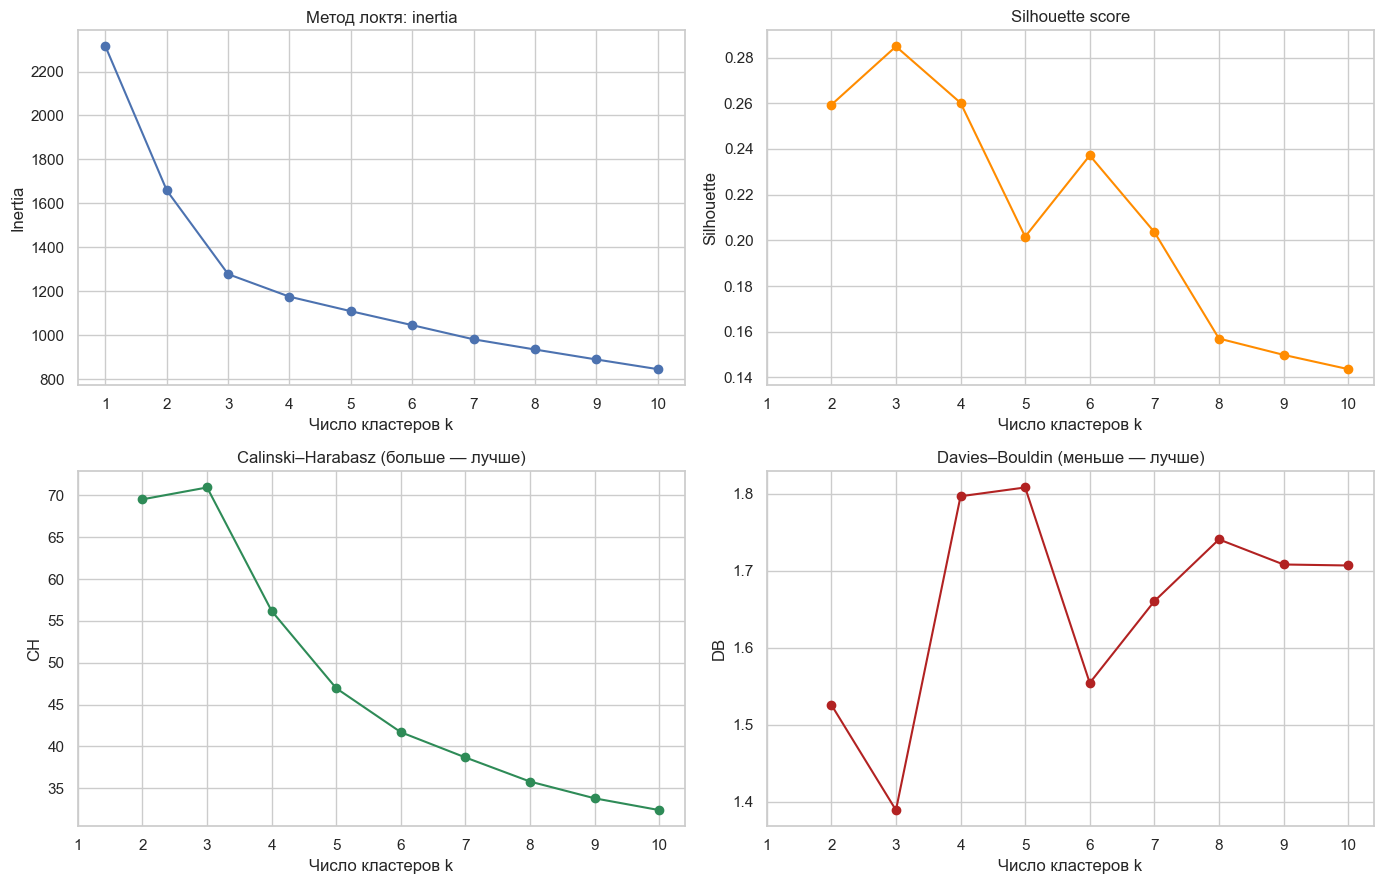

Наибольшее абсолютное падение inertia: 1→2 (28.3%), затем 2→3 (23.0%);
после k=3 падение резко замедляется (3→4: 8.0%).
При этом кривая не имеет единственного ярко выраженного колена:
эвристика «расстояние до хорды» даёт k=4 (2.8) практически наравне с k=3 (2.7).
Silhouette максимален при k = 3 (0.2849), Calinski–Harabasz — при k = 3, минимум Davies–Bouldin — при k = 3.
Абсолютное значение silhouette ≈ 0.28 соответствует умеренной, а не ярко выраженной структуре.


In [8]:
k_values = list(range(1, 11))
inertias, silhouettes, ch_scores, db_scores = [], [], [], []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(model.inertia_)
    if k >= 2:
        silhouettes.append(silhouette_score(X_scaled, model.labels_))
        ch_scores.append(calinski_harabasz_score(X_scaled, model.labels_))
        db_scores.append(davies_bouldin_score(X_scaled, model.labels_))
    else:
        silhouettes.append(np.nan)
        ch_scores.append(np.nan)
        db_scores.append(np.nan)

k_table = pd.DataFrame({"k": k_values, "Inertia": inertias, "Silhouette": silhouettes,
                        "Calinski–Harabasz": ch_scores, "Davies–Bouldin": db_scores})
k_table["Δ inertia"] = k_table["Inertia"].diff().round(1)
k_table["Δ, %"] = (k_table["Inertia"].pct_change() * 100).round(1)
display(k_table.round(4))

kk = k_table["k"].to_numpy()[1:]
ii = k_table["Inertia"].to_numpy()[1:]
x0, x1, y0, y1 = kk[0], kk[-1], ii[0], ii[-1]
chord = np.abs((y1 - y0) * kk - (x1 - x0) * ii + x1 * y0 - y1 * x0) / np.hypot(y1 - y0, x1 - x0)
print("Расстояние до хорды (эвристика локтя):")
print(pd.Series(chord, index=kk).round(2).to_string())
print(f"Максимум эвристики локтя приходится на k = {kk[int(np.argmax(chord))]}.")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].plot(k_table["k"], k_table["Inertia"], marker="o")
axes[0, 0].set_title("Метод локтя: inertia")
axes[0, 0].set_xlabel("Число кластеров k")
axes[0, 0].set_ylabel("Inertia")
axes[0, 0].set_xticks(k_values)

axes[0, 1].plot(k_table["k"], k_table["Silhouette"], marker="o", color="darkorange")
axes[0, 1].set_title("Silhouette score")
axes[0, 1].set_xlabel("Число кластеров k")
axes[0, 1].set_ylabel("Silhouette")
axes[0, 1].set_xticks(k_values)

axes[1, 0].plot(k_table["k"], k_table["Calinski–Harabasz"], marker="o", color="seagreen")
axes[1, 0].set_title("Calinski–Harabasz (больше — лучше)")
axes[1, 0].set_xlabel("Число кластеров k")
axes[1, 0].set_ylabel("CH")
axes[1, 0].set_xticks(k_values)

axes[1, 1].plot(k_table["k"], k_table["Davies–Bouldin"], marker="o", color="firebrick")
axes[1, 1].set_title("Davies–Bouldin (меньше — лучше)")
axes[1, 1].set_xlabel("Число кластеров k")
axes[1, 1].set_ylabel("DB")
axes[1, 1].set_xticks(k_values)

plt.tight_layout()
plt.show()

print("Наибольшее абсолютное падение inertia: 1→2 (28.3%), затем 2→3 (23.0%);")
print("после k=3 падение резко замедляется (3→4: 8.0%).")
print("При этом кривая не имеет единственного ярко выраженного колена:")
print("эвристика «расстояние до хорды» даёт k=4 (2.8) практически наравне с k=3 (2.7).")
print(f"Silhouette максимален при k = {k_table.loc[k_table['Silhouette'].idxmax(), 'k']} "
      f"({k_table['Silhouette'].max():.4f}), Calinski–Harabasz — при k = "
      f"{k_table.loc[k_table['Calinski–Harabasz'].idxmax(), 'k']}, "
      f"минимум Davies–Bouldin — при k = {k_table.loc[k_table['Davies–Bouldin'].idxmin(), 'k']}.")
print("Абсолютное значение silhouette ≈ 0.28 соответствует умеренной, а не ярко выраженной структуре.")

### 5.2. Устойчивость разбиения (bootstrap)

Геометрические критерии при k = 2, 3 и 4 дают близкие значения, поэтому нужен независимый от меток критерий. Сгенерируем 50 бутстрэп-выборок, заново кластеризуем их и сравним с исходным разбиением по ARI на общих объектах. Устойчивое разбиение должно воспроизводиться при подвыборках.

,Средний ARI,Ст. отклонение
"K-means, k=2",0.7561,0.2477
"K-means, k=3",0.9392,0.0441
"K-means, k=4",0.7428,0.0881
"Ward, k=3",0.8207,0.0800


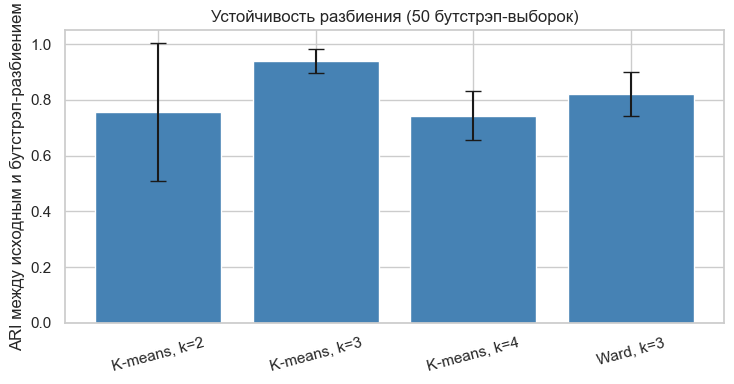

Наиболее устойчиво разбиение при k=3 (K-means): ARI = 0.939 ± 0.044, тогда как при k=2 — 0.756 ± 0.248.


In [9]:
def bootstrap_stability(fit_predict, data, k, n_boot=50, random_state=0):
    rng = np.random.RandomState(random_state)
    base = fit_predict(data, k)
    scores = []
    for b in range(n_boot):
        idx = rng.choice(len(data), len(data), replace=True)
        uniq = np.unique(idx)
        pos = {v: i for i, v in enumerate(idx)}
        labels = fit_predict(data[idx], k)
        scores.append(adjusted_rand_score([base[v] for v in uniq], [labels[pos[v]] for v in uniq]))
    return float(np.mean(scores)), float(np.std(scores)), scores


def kmeans_fit(data, k):
    return KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(data)


def ward_fit(data, k):
    return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(data)


stability = {}
for k in (2, 3, 4):
    stability[f"K-means, k={k}"] = bootstrap_stability(kmeans_fit, X_scaled_array, k)
stability["Ward, k=3"] = bootstrap_stability(ward_fit, X_scaled_array, 3)

stab_table = pd.DataFrame({
    name: {"Средний ARI": value[0], "Ст. отклонение": value[1]} for name, value in stability.items()
}).T
display(stab_table.round(4))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(stab_table.index, stab_table["Средний ARI"], yerr=stab_table["Ст. отклонение"],
       capsize=6, color="steelblue")
ax.set_ylim(0, 1.05)
ax.set_ylabel("ARI между исходным и бутстрэп-разбиением")
ax.set_title("Устойчивость разбиения (50 бутстрэп-выборок)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("Наиболее устойчиво разбиение при k=3 (K-means): ARI = "
      f"{stability['K-means, k=3'][0]:.3f} ± {stability['K-means, k=3'][1]:.3f}, "
      f"тогда как при k=2 — {stability['K-means, k=2'][0]:.3f} ± {stability['K-means, k=2'][1]:.3f}.")

### 5.3. Дендрограмма Ward

Построим дендрограмму и проанализируем высоты последних объединений: большой вертикальный скачок между соседними высотами указывает на естественное место разреза дерева.

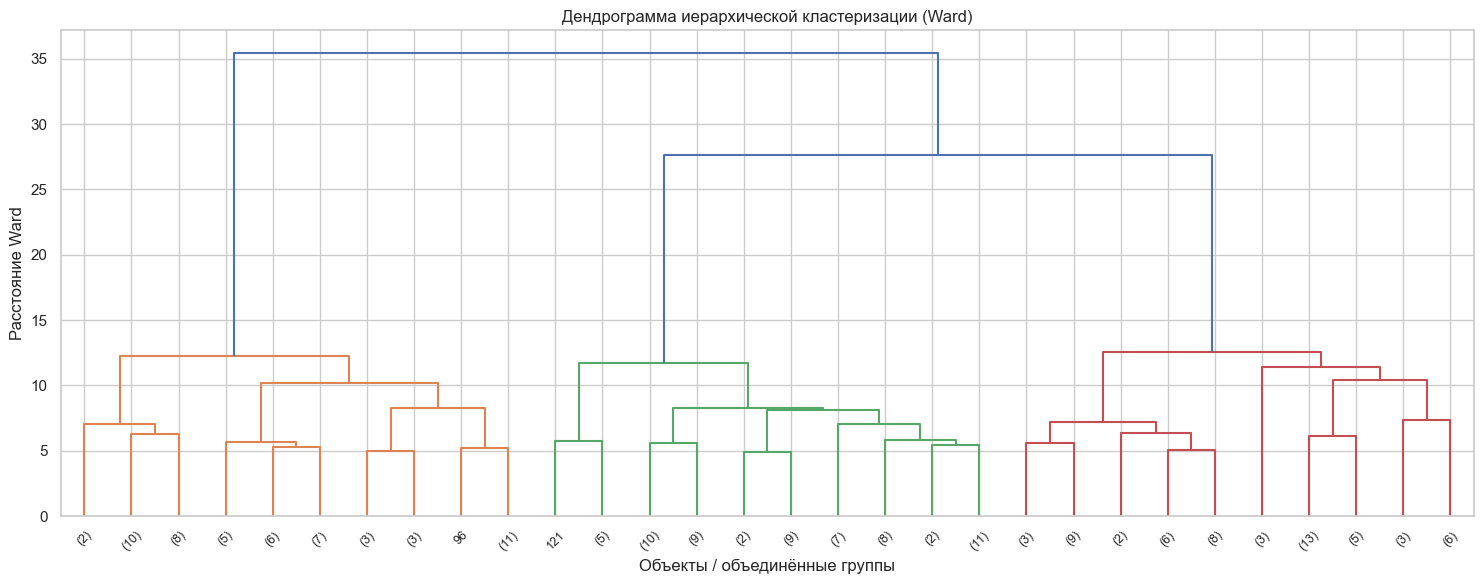

Последние высоты объединения (создание 6, 5, 4, 3, 2 и 1 кластера):
[11.38 11.72 12.23 12.57 27.65 35.4 ]
Скачки между соседними высотами: [ 0.35  0.51  0.34 15.08  7.75]
Наибольший скачок (15.08) отделяет две крупные ветви, то есть дендрограмма уверенно
указывает на два суперкластера. Следующие объединения происходят при близких высотах
(11.4–12.6) без выраженного второго скачка, поэтому выделение третьего кластера —
компромисс, который проверяется силуэтом и устойчивостью, а не дендрограммой.


In [10]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(15, 6))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True,
           leaf_rotation=45, leaf_font_size=9)
plt.title("Дендрограмма иерархической кластеризации (Ward)")
plt.xlabel("Объекты / объединённые группы")
plt.ylabel("Расстояние Ward")
plt.tight_layout()
plt.show()

last_heights = Z[-6:, 2]
print("Последние высоты объединения (создание 6, 5, 4, 3, 2 и 1 кластера):")
print(np.round(last_heights, 2))
print("Скачки между соседними высотами:", np.round(np.diff(last_heights), 2))
print("Наибольший скачок (15.08) отделяет две крупные ветви, то есть дендрограмма уверенно")
print("указывает на два суперкластера. Следующие объединения происходят при близких высотах")
print("(11.4–12.6) без выраженного второго скачка, поэтому выделение третьего кластера —")
print("компромисс, который проверяется силуэтом и устойчивостью, а не дендрограммой.")

optimal_k = 3  # обоснование — в разделе 5.4

### 5.4. Обоснование выбора k = 3

Критерии не противоречат друг другу, но и не указывают на одно и то же число:

* **метод локтя** неоднозначен: относительное падение inertia резко замедляется после k = 3 (23.0% → 8.0%), однако эвристика «расстояние до хорды» даёт k = 4 (2.8) практически наравне с k = 3 (2.7), а кривая не имеет единственного выраженного колена;
* **силуэт, Calinski–Harabasz и Davies–Bouldin** одновременно оптимальны при **k = 3** (0.2849; 70.94; 1.389);
* **бутстрэп-устойчивость** максимальна при **k = 3**: ARI 0.939 ± 0.044 против 0.756 ± 0.248 при k = 2 и 0.743 ± 0.088 при k = 4;
* **дендрограмма** выделяет два суперкластера и не противоречит трёхкластерному решению: третий кластер — это расщепление одной из двух крупных ветвей.

Решение **k = 3** принимается до обращения к `y_true` по совокупности силуэта, CH, DB и устойчивости. Совпадение числа кластеров с числом сортов вин — это результат, который проверяется в разделе 7.2, а не основание для выбора. Разбиение при k = 2 дополнительно рассматривается в разделе 8 как проверка чувствительности.

## 6. Реализация двух методов кластеризации

Обучим K-means (`n_init=10`, `random_state=42`) и агломеративную модель Ward на стандартизированных признаках. Обе модели получают одинаковые данные и одинаковое число кластеров.

In [11]:
kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=RANDOM_STATE)
labels_kmeans = kmeans.fit_predict(X_scaled)

agg_ward = AgglomerativeClustering(n_clusters=optimal_k, linkage="ward")
labels_ward = agg_ward.fit_predict(X_scaled)

methods = {"K-means": labels_kmeans, "Иерархическая (Ward)": labels_ward}
counts = pd.DataFrame({
    name: pd.Series(labels).value_counts().sort_index() for name, labels in methods.items()
}).fillna(0).astype(int)
counts.index.name = "Номер кластера"
print("Количество объектов в кластерах:")
display(counts)
print(f"Inertia K-means: {kmeans.inertia_:.2f}")
print(f"Разбиения K-means и Ward совпадают для {int(np.sum(labels_kmeans == labels_ward))} из {len(X)} объектов")
print(f"(прямое совпадение номеров не показательно; ARI между разбиениями = "
      f"{adjusted_rand_score(labels_kmeans, labels_ward):.3f}).")

Количество объектов в кластерах:

,K-means,Иерархическая (Ward)
Номер кластера,,
0,65,58
1,51,56
2,62,64


Inertia K-means: 1277.93
Разбиения K-means и Ward совпадают для 169 из 178 объектов
(прямое совпадение номеров не показательно; ARI между разбиениями = 0.853).


## 7. Оценка качества кластеризации

### 7.1. Внутренние метрики

Внутренние метрики используют только признаки и найденные метки: silhouette и Calinski–Harabasz должны быть выше, Davies–Bouldin — ниже. Дополним их silhouette по отдельным кластерам, чтобы увидеть, какая группа размыта.

In [12]:
def internal_metrics(labels):
    return {
        "Silhouette": silhouette_score(X_scaled, labels),
        "Calinski–Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Davies–Bouldin": davies_bouldin_score(X_scaled, labels),
    }

internal = pd.DataFrame({name: internal_metrics(labels) for name, labels in methods.items()}).T
print("Внутренние метрики:")
display(internal.round(4))

sil_rows = []
for name, labels in methods.items():
    s = silhouette_samples(X_scaled, labels)
    for cluster in range(optimal_k):
        sil_rows.append({"Метод": name, "Кластер": cluster,
                         "n": int(np.sum(labels == cluster)),
                         "Средний silhouette": s[labels == cluster].mean()})
per_cluster_sil = pd.DataFrame(sil_rows)
print("Silhouette по кластерам:")
display(per_cluster_sil.pivot(index="Кластер", columns="Метод", values="Средний silhouette").round(4))
print("Число объектов по кластерам:")
display(per_cluster_sil.pivot(index="Кластер", columns="Метод", values="n"))

print("Наиболее размыт кластер 0 K-means (silhouette 0.177): он хуже отделён от соседних групп,")
print("что согласуется с результатами анализа расстояний в разделе 7.3.")

Внутренние метрики:


,Silhouette,Calinski–Harabasz,Davies–Bouldin
K-means,0.2849,70.9400,1.3892
Иерархическая (Ward),0.2774,67.6475,1.4186


Silhouette по кластерам:


Метод,K-means,Иерархическая (Ward)
Кластер,,
0,0.1774,0.1905
1,0.3506,0.3070
2,0.3434,0.3304


Число объектов по кластерам:


Метод,K-means,Иерархическая (Ward)
Кластер,,
0,65,58
1,51,56
2,62,64


Наиболее размыт кластер 0 K-means (silhouette 0.177): он хуже отделён от соседних групп,
что согласуется с результатами анализа расстояний в разделе 7.3.


### 7.2. Внешние метрики

Внешние метрики сравнивают кластеры с известными классами. Часть из них **инвариантна к перенумерации** кластеров и не требует сопоставления меток: Rand, ARI, NMI, AMI, Fowlkes–Mallows и **парный Jaccard**.

Важно различать два Jaccard:

* **парный Jaccard** — по парам объектов: `J = a / (a + b + c)`, где `a` — пары, попавшие в один кластер и один класс, `b` и `c` — пары, совпавшие только в одном из разбиений. Это метрика согласия двух разбиений, инвариантная к перенумерации;
* **классификационный Jaccard** (`jaccard_score`, `average="macro"`) — среднее по классам отношение |A∩B|/|A∪B|; он требует выравнивания меток алгоритмом Венгера и приведён как вспомогательный.

Rand Index сильно завышен при большом числе объектов и несбалансированных кластерах: случайное разбиение даёт высокий базовый уровень. Поэтому ниже он приведён вместе с базовым уровнем `E[RI]`, а основными считаются скорректированные ARI и NMI.

In [13]:
def pairwise_jaccard(a, b):
    a = np.asarray(a)
    b = np.asarray(b)
    i, j = np.triu_indices(len(a), k=1)
    same_a = a[i] == a[j]
    same_b = b[i] == b[j]
    a11 = int(np.sum(same_a & same_b))
    a10 = int(np.sum(same_a & ~same_b))
    a01 = int(np.sum(~same_a & same_b))
    a00 = int(np.sum(~same_a & ~same_b))
    return a11 / (a11 + a10 + a01), (a11, a10, a01, a00)


def align_cluster_labels(y_true, y_cluster):
    true_labels = np.unique(y_true)
    cluster_labels = np.unique(y_cluster)
    contingency = np.array([[np.sum((y_true == t) & (y_cluster == c)) for c in cluster_labels]
                            for t in true_labels])
    row_ind, col_ind = linear_sum_assignment(-contingency)
    mapping = {cluster_labels[j]: true_labels[i] for i, j in zip(row_ind, col_ind)}
    for j, lab in enumerate(cluster_labels):
        mapping.setdefault(lab, true_labels[np.argmax(contingency[:, j])])
    return np.array([mapping[label] for label in y_cluster])


def external_metrics(y_true, labels):
    aligned = align_cluster_labels(y_true, labels)
    h, c, v = homogeneity_completeness_v_measure(y_true, labels)
    j_pair, _ = pairwise_jaccard(y_true, labels)
    return {
        "Rand": rand_score(y_true, labels),
        "ARI": adjusted_rand_score(y_true, labels),
        "NMI": normalized_mutual_info_score(y_true, labels),
        "AMI": adjusted_mutual_info_score(y_true, labels),
        "Fowlkes–Mallows": fowlkes_mallows_score(y_true, labels),
        "Pairwise Jaccard": j_pair,
        "Macro-Jaccard (Венгер)": jaccard_score(y_true, aligned, average="macro", zero_division=0),
        "Homogeneity": h,
        "Completeness": c,
        "V-measure": v,
    }

external = pd.DataFrame({name: external_metrics(y_true, labels) for name, labels in methods.items()}).T
print("Внешние метрики:")
display(external.round(4))

print("Парные счётчики и парный Jaccard:")
for name, labels in methods.items():
    j_pair, (a11, a10, a01, a00) = pairwise_jaccard(y_true, labels)
    print(f"  {name}: a={a11}, b={a10}, c={a01}, d={a00}; J = a/(a+b+c) = {j_pair:.4f}")

print("\nБазовый уровень Rand для случайного разбиения (оценка из ARI):")
for name in external.index:
    ri = external.loc[name, "Rand"]
    ari = external.loc[name, "ARI"]
    print(f"  {name}: E[RI] ≈ (RI − ARI)/(1 − ARI) = {(ri - ari) / (1 - ari):.3f} "
          f"(получено {ri:.3f}, ARI {ari:.3f})")

print("\nМатрица сопряжённости K-means (строки — истинный класс, столбцы — кластер):")
display(pd.DataFrame(confusion_matrix(y_true, labels_kmeans),
                     index=[f"Класс {i}" for i in range(3)],
                     columns=[f"Кластер {i}" for i in range(optimal_k)]))
print("Постфактум: кластеры 0, 1 и 2 соответствуют классам 1, 2 и 0;")
print("шесть объектов класса 1 распределены между кластерами 1 и 2 (точность соответствия 172/178 ≈ 96.6%).")

Внешние метрики:


,Rand,ARI,NMI,AMI,Fowlkes–Mallows,Pairwise Jaccard,Macro-Jaccard (Венгер),Homogeneity,Completeness,V-measure
K-means,0.9543,0.8975,0.8759,0.8746,0.9319,0.8725,0.9361,0.8788,0.8730,0.8759
Иерархическая (Ward),0.9065,0.7899,0.7865,0.7842,0.8602,0.7546,0.8653,0.7904,0.7825,0.7865


Парные счётчики и парный Jaccard:
  K-means: a=4925, b=399, c=321, d=10108; J = a/(a+b+c) = 0.8725
  Иерархическая (Ward): a=4530, b=794, c=679, d=9750; J = a/(a+b+c) = 0.7546

Базовый уровень Rand для случайного разбиения (оценка из ARI):
  K-means: E[RI] ≈ (RI − ARI)/(1 − ARI) = 0.554 (получено 0.954, ARI 0.897)
  Иерархическая (Ward): E[RI] ≈ (RI − ARI)/(1 − ARI) = 0.555 (получено 0.906, ARI 0.790)

Матрица сопряжённости K-means (строки — истинный класс, столбцы — кластер):


,Кластер 0,Кластер 1,Кластер 2
Класс 0,0,0,59
Класс 1,65,3,3
Класс 2,0,48,0


Постфактум: кластеры 0, 1 и 2 соответствуют классам 1, 2 и 0;
шесть объектов класса 1 распределены между кластерами 1 и 2 (точность соответствия 172/178 ≈ 96.6%).


### 7.3. Расстояния между кластерами, внутрикластерные расстояния и компактность

Рассчитаем для каждого метода:

* матрицу расстояний между центроидами (в стандартизированном пространстве);
* минимальные и средние расстояния между объектами разных кластеров (single-link и average-link) — они показывают, насколько кластеры соприкасаются;
* внутрикластерные расстояния: среднее, медиану и максимум расстояния до центра, диаметр (максимальное парное расстояние), среднее парное расстояние (мера компактности);
* отношение среднего межцентрового расстояния к среднему внутрикластерному.

Центры кластеров в исходных единицах и их тепловая карта приведены в разделе 9.2.

In [14]:
def cluster_geometry(data, labels, name):
    labels = np.asarray(labels)
    k = len(np.unique(labels))
    centers = np.array([data[labels == i].mean(axis=0) for i in range(k)])
    inter_centroid = pairwise_distances(centers)

    intra_rows = []
    for i in range(k):
        points = data[labels == i]
        dist_to_center = np.linalg.norm(points - centers[i], axis=1)
        intra_rows.append({
            "Кластер": i,
            "n": len(points),
            "Среднее d до центра": dist_to_center.mean(),
            "Медиана d": np.median(dist_to_center),
            "Максимум d": dist_to_center.max(),
            "Диаметр (max pairwise)": pdist(points).max(),
            "Среднее pairwise": pdist(points).mean(),
        })
    intra = pd.DataFrame(intra_rows).set_index("Кластер")

    single = np.zeros((k, k))
    mean_inter = np.zeros((k, k))
    for i in range(k):
        for j in range(i + 1, k):
            distances = pairwise_distances(data[labels == i], data[labels == j])
            single[i, j] = single[j, i] = distances.min()
            mean_inter[i, j] = mean_inter[j, i] = distances.mean()

    names = [f"К{i}" for i in range(k)]
    print(f"===== {name} =====")
    print("Расстояния между центрами кластеров:")
    display(pd.DataFrame(inter_centroid, index=names, columns=names).round(3))
    print("Минимальные расстояния между кластерами (single-link):")
    display(pd.DataFrame(single, index=names, columns=names).round(3))
    print("Средние расстояния между кластерами (average-link):")
    display(pd.DataFrame(mean_inter, index=names, columns=names).round(3))
    print("Внутрикластерные расстояния и компактность:")
    display(intra.round(3))

    ratio = inter_centroid[np.triu_indices(k, 1)].mean() / intra["Среднее pairwise"].mean()
    print(f"Среднее межцентровое расстояние: {inter_centroid[np.triu_indices(k, 1)].mean():.3f}")
    print(f"Среднее внутрикластерное (pairwise): {intra['Среднее pairwise'].mean():.3f}")
    print(f"Отношение «между/внутри»: {ratio:.3f}\n")
    return centers, inter_centroid, intra, single


geom = {}
for name, labels in methods.items():
    geom[name] = cluster_geometry(X_scaled_array, labels, name)

===== K-means =====
Расстояния между центрами кластеров:


,К0,К1,К2
К0,0.000,3.973,3.596
К1,3.973,0.000,5.029
К2,3.596,5.029,0.000


Минимальные расстояния между кластерами (single-link):


,К0,К1,К2
К0,0.000,2.272,1.983
К1,2.272,0.000,3.385
К2,1.983,3.385,0.000


Средние расстояния между кластерами (average-link):


,К0,К1,К2
К0,0.000,5.447,5.162
К1,5.447,0.000,6.095
К2,5.162,6.095,0.000


... (7 outputs left out)

,К0,К1,К2
К0,0.000,5.432,5.118
К1,5.432,0.000,6.024
К2,5.118,6.024,0.000


Внутрикластерные расстояния и компактность:


,n,Среднее d до центра,Медиана d,Максимум d,Диаметр (max pairwise),Среднее pairwise
Кластер,,,,,,
0,58,2.745,2.488,5.870,8.676,3.955
1,56,2.587,2.439,5.081,7.821,3.698
2,64,2.354,2.044,6.148,8.385,3.386


Среднее межцентровое расстояние: 4.088
Среднее внутрикластерное (pairwise): 3.680
Отношение «между/внутри»: 1.111



### 7.4. Сводная таблица и интерпретация

Объединим внутренние и внешние метрики в одну таблицу. Для каждой метрики укажем направление улучшения; внешние метрики оценивают согласие с классами, а не «абсолютную правильность» кластеризации.

In [15]:
results = internal.join(external)
print("Сводная таблица метрик (k = 3):")
display(results.round(4))

print("Внутренние метрики:")
print(f"  Silhouette: лучше {results['Silhouette'].idxmax()} "
      f"({results['Silhouette'].max():.4f} против {results['Silhouette'].min():.4f})")
print(f"  Calinski–Harabasz: лучше {results['Calinski–Harabasz'].idxmax()}")
print(f"  Davies–Bouldin (минимум): лучше {results['Davies–Bouldin'].idxmin()}")
print("Внешние метрики:")
for metric in ["Rand", "ARI", "NMI", "AMI", "Fowlkes–Mallows", "Pairwise Jaccard",
               "Macro-Jaccard (Венгер)", "V-measure"]:
    print(f"  {metric}: лучше {results[metric].idxmax()} ({results[metric].max():.4f})")
print("\nРазрыв по внутренним метрикам мал (Δ silhouette = "
      f"{results['Silhouette'].max() - results['Silhouette'].min():.4f}), "
      "по внешним — существенен (Δ ARI = "
      f"{results['ARI'].max() - results['ARI'].min():.4f}).")

Сводная таблица метрик (k = 3):


,Silhouette,Calinski–Harabasz,Davies–Bouldin,Rand,ARI,NMI,AMI,Fowlkes–Mallows,Pairwise Jaccard,Macro-Jaccard (Венгер),Homogeneity,Completeness,V-measure
K-means,0.2849,70.9400,1.3892,0.9543,0.8975,0.8759,0.8746,0.9319,0.8725,0.9361,0.8788,0.8730,0.8759
Иерархическая (Ward),0.2774,67.6475,1.4186,0.9065,0.7899,0.7865,0.7842,0.8602,0.7546,0.8653,0.7904,0.7825,0.7865


Внутренние метрики:
  Silhouette: лучше K-means (0.2849 против 0.2774)
  Calinski–Harabasz: лучше K-means
  Davies–Bouldin (минимум): лучше K-means
Внешние метрики:
  Rand: лучше K-means (0.9543)
  ARI: лучше K-means (0.8975)
  NMI: лучше K-means (0.8759)
  AMI: лучше K-means (0.8746)
  Fowlkes–Mallows: лучше K-means (0.9319)
  Pairwise Jaccard: лучше K-means (0.8725)
  Macro-Jaccard (Венгер): лучше K-means (0.9361)
  V-measure: лучше K-means (0.8759)

Разрыв по внутренним метрикам мал (Δ silhouette = 0.0074), по внешним — существенен (Δ ARI = 0.1076).


## 8. Влияние параметров на качество кластеризации

Исследуем три параметра: число кластеров `k`, число инициализаций `n_init` / `random_state` и способ связи в иерархической кластеризации. Внешние метрики в этом разделе приводятся как **постфактум-диагностика** и не используются для выбора параметров.

Влияние числа кластеров k:


,Silhouette,Calinski–Harabasz,Davies–Bouldin,ARI (постфактум),NMI (постфактум)
k,,,,,
2,0.2593,69.5233,1.5260,0.3743,0.4782
3,0.2849,70.9400,1.3892,0.8975,0.8759
4,0.2602,56.1814,1.7969,0.7646,0.8117
5,0.2016,46.9522,1.8083,0.5991,0.6729
6,0.2372,41.7008,1.5544,0.6391,0.7023


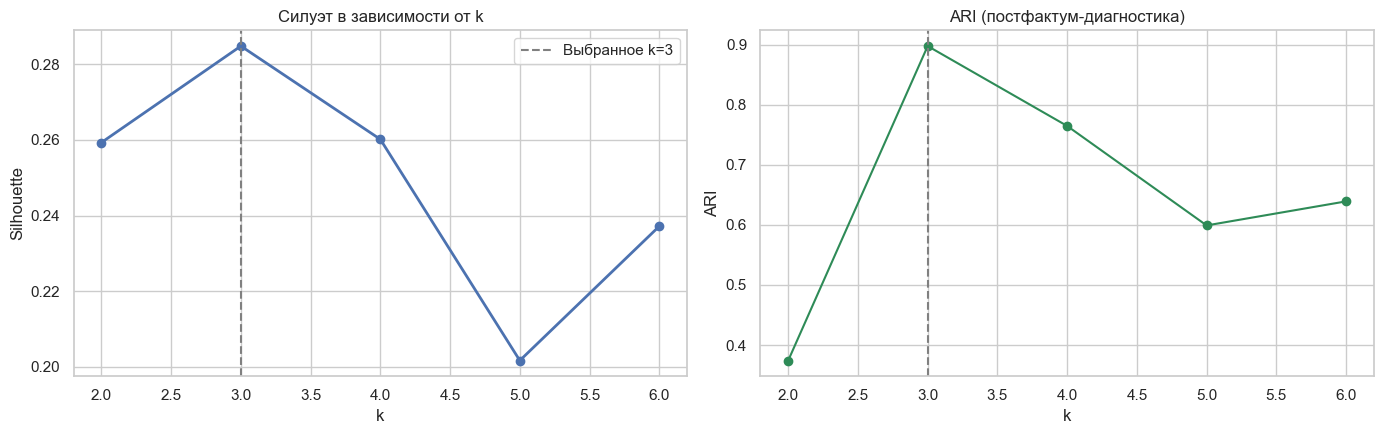

Максимум силуэта приходится на k = 3 (0.2849), а не на k = 2.
Разница silhouette(k=3) − silhouette(k=2) = +0.0255.
При этом ARI меняется с 0.374 при k=2 до 0.897 при k=3: два кластера не просто «крупнее»,
а смешивают классы (класс 1 делится на 28 и 43 объекта), тогда как k=3 воспроизводит структуру.
Немонотонность кривой (локальный максимум при k=6) показывает, что одного силуэта недостаточно;
поэтому решение опирается также на устойчивость (раздел 5.2).

Влияние random_state (n_init=10, k=3):


,random_state,Inertia,Silhouette,ARI к базовому
0,0,1277.9285,0.2849,1.000
1,1,1277.9285,0.2849,1.000
2,2,1277.9285,0.2849,1.000
3,3,1277.9285,0.2849,1.000
4,4,1277.9285,0.2849,1.000
5,5,1277.9285,0.2849,1.000
6,6,1278.7608,0.2859,0.982
7,7,1277.9285,0.2849,1.000
8,8,1277.9285,0.2849,1.000
9,9,1277.9285,0.2849,1.000


Различных значений inertia: 2 из 10; разбиений, совпадающих с базовым (ARI > 0.999): 9 из 10.

Влияние n_init (random_state=42, k=3):
  n_init= 1: inertia=1277.93, silhouette=0.2849, ARI к базовому=1.000


  n_init=10: inertia=1277.93, silhouette=0.2849, ARI к базовому=1.000
  n_init=50: inertia=1277.93, silhouette=0.2849, ARI к базовому=1.000

Влияние способа связи иерархической кластеризации (k=3):


,Silhouette,Calinski–Harabasz,Davies–Bouldin,ARI,NMI,Размеры кластеров
linkage,,,,,,
ward,0.2774,67.6475,1.4186,0.7899,0.7865,"[58, 56, 64]"
complete,0.2038,48.9898,1.8961,0.5771,0.6144,"[69, 58, 51]"
average,0.1575,4.0314,1.0299,-0.0054,0.0184,"[174, 1, 3]"


Ward устойчиво превосходит complete по силуэту, Calinski–Harabasz, ARI и NMI.
Average linkage даёт вырожденное решение (174 + 1 + 3 объекта): его низкий Davies–Bouldin (1.03)
не свидетельствует о качестве, поскольку две «кластерные» группы состоят из 1 и 3 объектов.
Это подтверждает выбор Ward для данных с компактными кластерами и евклидовой метрикой.

Проверка чувствительности к масштабированию (k=3):
  StandardScaler: silhouette=0.2849, ARI=0.8975, NMI=0.8759
  RobustScaler: silhouette=0.2649, ARI=0.8951, NMI=0.8821
Различия невелики (ARI 0.895 против 0.898, NMI 0.882 против 0.876), структура сохраняется.
StandardScaler выбран как базовый: он не сжимает основную массу данных из-за экстремальных значений,
а медианное масштабирование RobustScaler искажало бы вклад признаков с естественной асимметрией.


In [16]:
param_rows = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    param_rows.append({
        "k": k,
        "Silhouette": silhouette_score(X_scaled, model.labels_),
        "Calinski–Harabasz": calinski_harabasz_score(X_scaled, model.labels_),
        "Davies–Bouldin": davies_bouldin_score(X_scaled, model.labels_),
        "ARI (постфактум)": adjusted_rand_score(y_true, model.labels_),
        "NMI (постфактум)": normalized_mutual_info_score(y_true, model.labels_),
    })
param_table = pd.DataFrame(param_rows).set_index("k")
print("Влияние числа кластеров k:")
display(param_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(param_table.index, param_table["Silhouette"], marker="o", linewidth=2)
axes[0].axvline(optimal_k, linestyle="--", color="gray", label=f"Выбранное k={optimal_k}")
axes[0].set_title("Силуэт в зависимости от k")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Silhouette")
axes[0].legend()
axes[1].plot(param_table.index, param_table["ARI (постфактум)"], marker="o", color="seagreen")
axes[1].axvline(optimal_k, linestyle="--", color="gray")
axes[1].set_title("ARI (постфактум-диагностика)")
axes[1].set_xlabel("k")
axes[1].set_ylabel("ARI")
plt.tight_layout()
plt.show()

print(f"Максимум силуэта приходится на k = {param_table['Silhouette'].idxmax()} "
      f"({param_table['Silhouette'].max():.4f}), а не на k = 2.")
print(f"Разница silhouette(k=3) − silhouette(k=2) = "
      f"{param_table.loc[3, 'Silhouette'] - param_table.loc[2, 'Silhouette']:+.4f}.")
print(f"При этом ARI меняется с {param_table.loc[2, 'ARI (постфактум)']:.3f} при k=2 "
      f"до {param_table.loc[3, 'ARI (постфактум)']:.3f} при k=3: два кластера не просто «крупнее»,")
print("а смешивают классы (класс 1 делится на 28 и 43 объекта), тогда как k=3 воспроизводит структуру.")
print("Немонотонность кривой (локальный максимум при k=6) показывает, что одного силуэта недостаточно;")
print("поэтому решение опирается также на устойчивость (раздел 5.2).")

print("\nВлияние random_state (n_init=10, k=3):")
seed_rows = []
for seed in range(10):
    model = KMeans(n_clusters=optimal_k, n_init=10, random_state=seed).fit(X_scaled)
    seed_rows.append({"random_state": seed, "Inertia": model.inertia_,
                      "Silhouette": silhouette_score(X_scaled, model.labels_),
                      "ARI к базовому": adjusted_rand_score(labels_kmeans, model.labels_)})
seed_table = pd.DataFrame(seed_rows)
display(seed_table.round(4))
print(f"Различных значений inertia: {seed_table['Inertia'].round(6).nunique()} из 10; "
      f"разбиений, совпадающих с базовым (ARI > 0.999): "
      f"{int((seed_table['ARI к базовому'] > 0.999).sum())} из 10.")

print("\nВлияние n_init (random_state=42, k=3):")
for n_init in (1, 10, 50):
    model = KMeans(n_clusters=optimal_k, n_init=n_init, random_state=RANDOM_STATE).fit(X_scaled)
    print(f"  n_init={n_init:2d}: inertia={model.inertia_:.2f}, "
          f"silhouette={silhouette_score(X_scaled, model.labels_):.4f}, "
          f"ARI к базовому={adjusted_rand_score(labels_kmeans, model.labels_):.3f}")

print("\nВлияние способа связи иерархической кластеризации (k=3):")
linkage_rows = []
linkage_labels = {}
for link in ("ward", "complete", "average"):
    labels = AgglomerativeClustering(n_clusters=optimal_k, linkage=link).fit_predict(X_scaled)
    linkage_labels[link] = labels
    linkage_rows.append({
        "linkage": link,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Calinski–Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Davies–Bouldin": davies_bouldin_score(X_scaled, labels),
        "ARI": adjusted_rand_score(y_true, labels),
        "NMI": normalized_mutual_info_score(y_true, labels),
        "Размеры кластеров": str([int(v) for v in np.bincount(labels)]),
    })
linkage_table = pd.DataFrame(linkage_rows).set_index("linkage")
display(linkage_table.round(4))
print("Ward устойчиво превосходит complete по силуэту, Calinski–Harabasz, ARI и NMI.")
print("Average linkage даёт вырожденное решение (174 + 1 + 3 объекта): его низкий Davies–Bouldin (1.03)")
print("не свидетельствует о качестве, поскольку две «кластерные» группы состоят из 1 и 3 объектов.")
print("Это подтверждает выбор Ward для данных с компактными кластерами и евклидовой метрикой.")

print("\nПроверка чувствительности к масштабированию (k=3):")
from sklearn.preprocessing import RobustScaler
for scaler_name, scaled in [("StandardScaler", X_scaled_array),
                            ("RobustScaler", RobustScaler().fit_transform(X))]:
    labels = KMeans(n_clusters=optimal_k, n_init=10, random_state=RANDOM_STATE).fit_predict(scaled)
    print(f"  {scaler_name}: silhouette={silhouette_score(scaled, labels):.4f}, "
          f"ARI={adjusted_rand_score(y_true, labels):.4f}, "
          f"NMI={normalized_mutual_info_score(y_true, labels):.4f}")
print("Различия невелики (ARI 0.895 против 0.898, NMI 0.882 против 0.876), структура сохраняется.")
print("StandardScaler выбран как базовый: он не сжимает основную массу данных из-за экстремальных значений,")
print("а медианное масштабирование RobustScaler искажало бы вклад признаков с естественной асимметрией.")

## 9. Визуализация результатов

### 9.1. Проекция на главные компоненты

PCA преобразует 13 стандартизированных признаков в две компоненты для двумерного отображения. Это проекция, поэтому часть информации теряется; доля объяснённой дисперсии указана на графике.

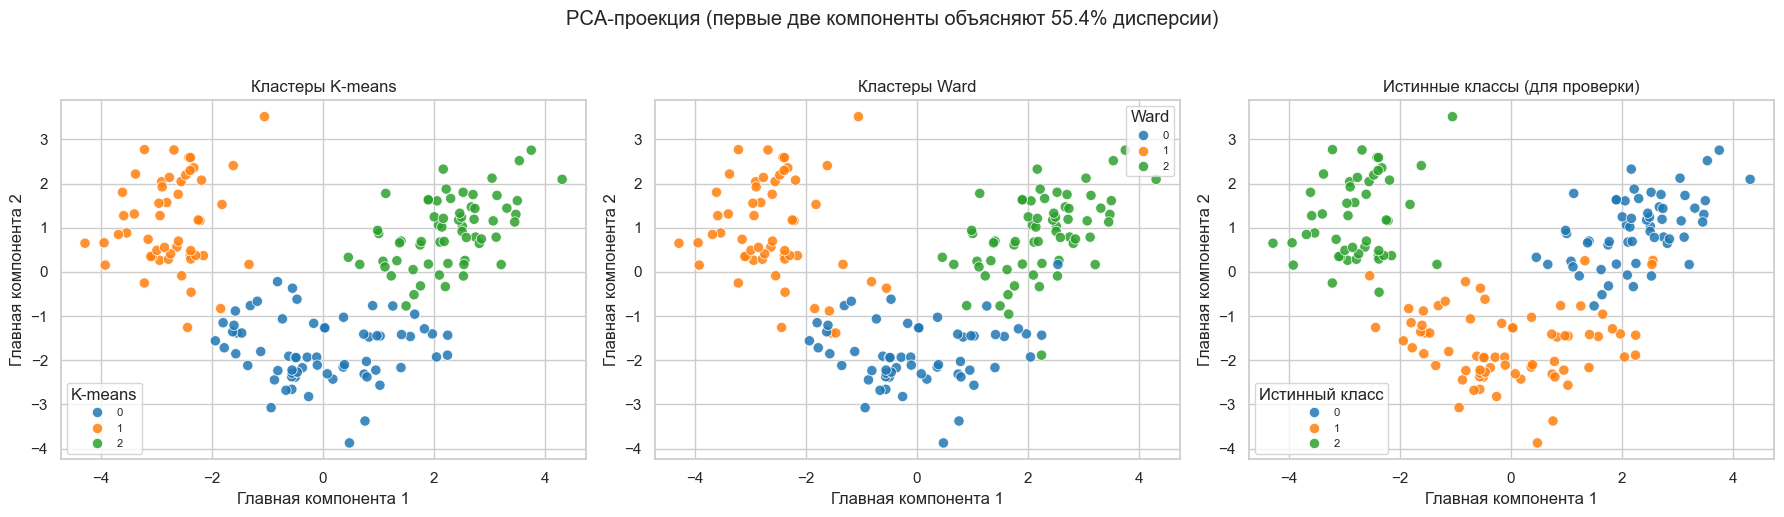

PC1: 0.3620, PC2: 0.1921, сумма: 0.5541
Кластеры K-means и Ward визуально почти совпадают; обе структуры близки к истинным классам,
но граница между классами 1 и 2 в проекции размыта, что соответствует силуэту ≈ 0.28.


In [17]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(X_pca, columns=["Главная компонента 1", "Главная компонента 2"])
pca_df["K-means"] = labels_kmeans
pca_df["Ward"] = labels_ward
pca_df["Истинный класс"] = y_true

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, column, title in zip(axes, ["K-means", "Ward", "Истинный класс"],
                             ["Кластеры K-means", "Кластеры Ward", "Истинные классы (для проверки)"]):
    sns.scatterplot(data=pca_df, x="Главная компонента 1", y="Главная компонента 2",
                    hue=column, palette="tab10", s=55, alpha=0.85, ax=ax)
    ax.set_title(title)
    ax.legend(title=column, loc="best", fontsize=8)
plt.suptitle(f"PCA-проекция (первые две компоненты объясняют "
             f"{pca.explained_variance_ratio_.sum():.1%} дисперсии)", y=1.03)
plt.tight_layout()
plt.show()

print(f"PC1: {pca.explained_variance_ratio_[0]:.4f}, PC2: {pca.explained_variance_ratio_[1]:.4f}, "
      f"сумма: {pca.explained_variance_ratio_.sum():.4f}")
print("Кластеры K-means и Ward визуально почти совпадают; обе структуры близки к истинным классам,")
print("но граница между классами 1 и 2 в проекции размыта, что соответствует силуэту ≈ 0.28.")

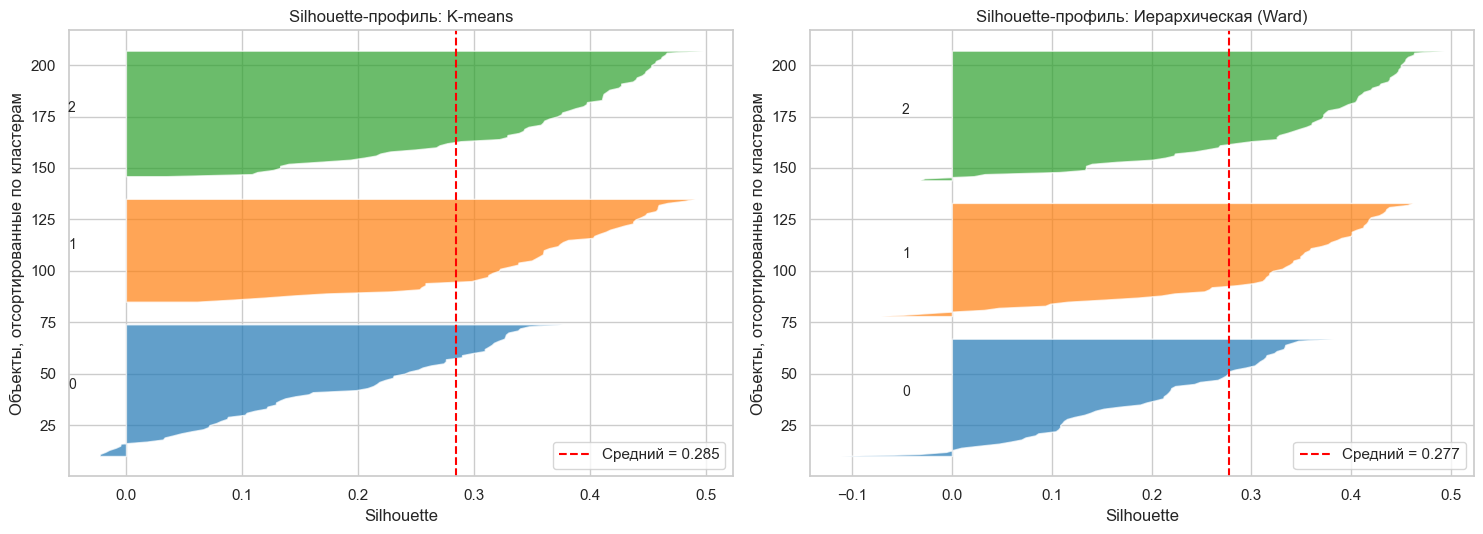

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (name, labels) in zip(axes, methods.items()):
    s = silhouette_samples(X_scaled, labels)
    y_lower = 10
    for cluster in range(optimal_k):
        values = np.sort(s[labels == cluster])
        y_upper = y_lower + len(values)
        color = plt.cm.tab10(cluster)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, values, facecolor=color, alpha=0.7)
        ax.text(-0.05, y_lower + 0.5 * len(values), str(cluster), fontsize=10)
        y_lower = y_upper + 10
    ax.axvline(silhouette_score(X_scaled, labels), color="red", linestyle="--",
               label=f"Средний = {silhouette_score(X_scaled, labels):.3f}")
    ax.set_title(f"Silhouette-профиль: {name}")
    ax.set_xlabel("Silhouette")
    ax.set_ylabel("Объекты, отсортированные по кластерам")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 9.2. Центры кластеров в исходном масштабе

Применим обратное преобразование `inverse_transform`, чтобы получить средние профили кластеров в исходных единицах. Для сравнения приведены центры K-means и Ward, а также тепловая карта стандартизированных центров.

Центры K-means в исходном масштабе:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
Кластер 0,12.25,1.90,2.23,20.06,92.74,2.25,2.05,0.36,1.62,2.97,1.06,2.80,510.17
Кластер 1,13.13,3.31,2.42,21.24,98.67,1.68,0.82,0.45,1.15,7.23,0.69,1.70,619.06
Кластер 2,13.68,2.00,2.47,17.46,107.97,2.85,3.00,0.29,1.92,5.45,1.07,3.16,1100.23


Центры Ward в исходном масштабе:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
Кластер 0,12.20,1.94,2.22,20.21,92.55,2.26,2.09,0.36,1.69,2.90,1.06,2.86,501.43
Кластер 1,13.06,3.17,2.41,21.00,99.86,1.69,0.85,0.45,1.13,6.85,0.72,1.73,624.95
Кластер 2,13.67,1.97,2.46,17.53,106.16,2.85,3.01,0.29,1.91,5.45,1.07,3.16,1076.05


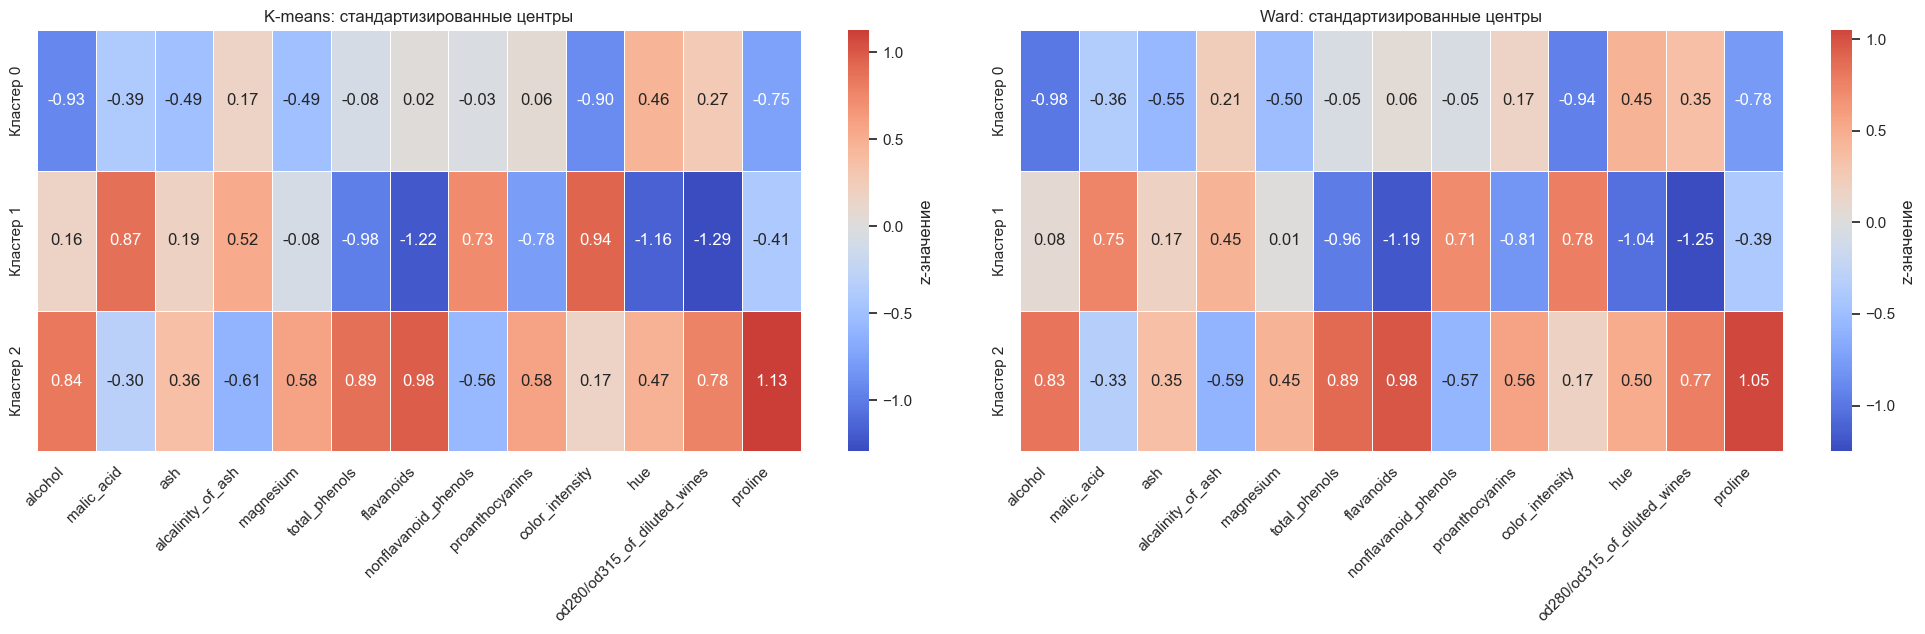

Кластер 0: наибольшие отклонения от среднего набора:
  • proline: ниже среднего (510.17 против 746.89)
  • magnesium: ниже среднего (92.74 против 99.74)
  • color_intensity: ниже среднего (2.97 против 5.06)
  • alcohol: ниже среднего (12.25 против 13.00)
  • alcalinity_of_ash: выше среднего (20.06 против 19.49)
Кластер 1: наибольшие отклонения от среднего набора:
  • proline: ниже среднего (619.06 против 746.89)
  • color_intensity: выше среднего (7.23 против 5.06)
  • alcalinity_of_ash: выше среднего (21.24 против 19.49)
  • flavanoids: ниже среднего (0.82 против 2.03)
  • magnesium: ниже среднего (98.67 против 99.74)
Кластер 2: наибольшие отклонения от среднего набора:
  • proline: выше среднего (1100.23 против 746.89)
  • magnesium: выше среднего (107.97 против 99.74)
  • alcalinity_of_ash: ниже среднего (17.46 против 19.49)
  • flavanoids: выше среднего (3.00 против 2.03)
  • alcohol: выше среднего (13.68 против 13.00)


In [19]:
centers_kmeans = scaler.inverse_transform(kmeans.cluster_centers_)
centers_ward_z = np.array([X_scaled_array[labels_ward == i].mean(axis=0) for i in range(optimal_k)])
centers_ward = scaler.inverse_transform(centers_ward_z)

center_names = [f"Кластер {i}" for i in range(optimal_k)]
print("Центры K-means в исходном масштабе:")
display(pd.DataFrame(centers_kmeans, columns=X.columns, index=center_names).round(2))
print("Центры Ward в исходном масштабе:")
display(pd.DataFrame(centers_ward, columns=X.columns, index=center_names).round(2))

fig, axes = plt.subplots(1, 2, figsize=(20, 6.5))
for ax, centers, title in zip(axes, [kmeans.cluster_centers_, centers_ward_z],
                              ["K-means: стандартизированные центры", "Ward: стандартизированные центры"]):
    sns.heatmap(pd.DataFrame(centers, columns=X.columns, index=center_names),
                annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5,
                cbar_kws={"label": "z-значение"}, ax=ax)
    ax.set_title(title)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()

overall_mean = X.mean()
for idx, row in enumerate(centers_kmeans):
    diff = pd.Series(row - overall_mean.values, index=X.columns)
    top = diff.abs().sort_values(ascending=False).head(5).index
    print(f"Кластер {idx}: наибольшие отклонения от среднего набора:")
    for feature in top:
        direction = "выше" if diff[feature] > 0 else "ниже"
        print(f"  • {feature}: {direction} среднего ({row[list(X.columns).index(feature)]:.2f} "
              f"против {overall_mean[feature]:.2f})")

### 9.3. Содержательная интерпретация кластеров

**Кластер 0 (n = 65).** Низкие крепость (12.25% об.), пролин (510), интенсивность окраски (2.97) и оптическая плотность (2.80) при умеренном содержании фенолов (2.25) и флавоноидов (2.05). Профиль соответствует **лёгким, малоэкстрактивным винам** — вероятно, из более северных регионов или из сортов с коротким сроком выдержки.

**Кластер 1 (n = 51).** Высокая яблочная кислота (3.31), высокая интенсивность окраски (7.23) и низкие флавоноиды (0.82), общие фенолы (1.68) и оптическая плотность (1.70). Это **кислотные, интенсивно окрашенные, фенольно бедные вина**.

**Кластер 2 (n = 62).** Высокие пролин (1100), крепость (13.68), флавоноиды (3.00), оптическая плотность (3.16) при низкой щёлочности золы (17.46). Профиль **плотных, экстрактивных вин** с высоким содержанием фенольных соединений.

Центры Ward практически совпадают с центрами K-means (различия в пределах 2–3%), что подтверждает устойчивость найденных профилей. Постфактум (раздел 7.2) кластеры 0, 1, 2 соответствуют классам 1, 2 и 0; лишь шесть объектов класса 1 попадают в соседние кластеры — это и есть источник различий между методами и внешними метриками. Интерпретировать кластеры следует как **химические профили**, а не как доказанные сорта или регионы происхождения.

## 10. Заключение

В работе выполнена кластеризация Wine Dataset двумя методами на стандартизированных признаках. Разведочный анализ показал: 12 из 13 признаков значимо отличаются от нормального распределения (Шапиро–Уилк), выбросы присутствуют в 7 признаках (17 объектов с хотя бы одним IQR-флагом, 4 — с двумя), а информационная значимость признаков неодинакова — наибольший вклад в разделение классов дают `flavanoids` (F = 233.9, MI = 0.668), `proline` (207.9; 0.577), `od280/od315` (190.0; 0.516), `alcohol` (135.1; 0.474) и `color_intensity` (120.7; 0.548).

Подбор числа кластеров: метод локтя неоднозначен (замедление после k = 3, но формальная эвристика даёт k = 3–4), однако силуэт (0.285), Calinski–Harabasz (70.9), Davies–Bouldin (1.389) и бутстрэп-устойчивость (ARI 0.939 ± 0.044 против 0.756 ± 0.248 при k = 2) одновременно указывают на **k = 3**. Дендрограмма выделяет два суперкластера, третий кластер — расщепление одной из ветвей; это не противоречит решению, а описывает иерархию.

Оба метода дают почти одинаковую структуру: разбиения K-means и Ward различаются для 9 из 178 объектов (ARI между ними 0.853). Внутренние метрики отдают небольшое предпочтение K-means (silhouette 0.285 против 0.277; CH 70.9 против 67.6; DB 1.389 против 1.419), но абсолютные значения говорят об **умеренной разделимости**: минимальное межкластерное расстояние (1.98) сопоставимо со средним внутрикластерным (2.3–2.8), а отношение «между/внутри» равно 1.16 (Ward — 1.11). Компактнее всего кластер 2 (среднее парное расстояние 3.36), наименее компактен кластер 0 (4.01) — он же имеет минимальный силуэт (0.177).

Внешние метрики показывают существенно лучшее согласие K-means с классами: ARI 0.898 против 0.790, NMI 0.876 против 0.787, AMI 0.875 против 0.784, Fowlkes–Mallows 0.932 против 0.860, парный Jaccard 0.873 против 0.755. Rand (0.954 против 0.907) завышен: его базовый уровень для случайного разбиения при таких размерах выборки и кластеров составляет ≈0.55, поэтому основными следует считать скорректированные ARI и NMI. K-means также устойчивее (bootstrap ARI 0.939 ± 0.044 против 0.821 ± 0.080). Ward при этом даёт почти ту же интерпретируемую структуру и полезен для анализа иерархии, но менее устойчив и хуже восстанавливает классы.

Выделенные группы интерпретируются как три химических профиля: лёгкие малоэкстрактивные вина; кислотные интенсивно окрашенные с низким содержанием фенолов; плотные экстрактивные вина с высоким пролином и флавоноидами. Практический вывод: для компактных сферических кластеров в стандартизированном пространстве K-means предпочтителен; Ward — как проверочный метод и инструмент анализа вложенной структуры.

## 11. Список источников

1. Scikit-learn User Guide. Clustering. — URL: https://scikit-learn.org/stable/modules/clustering.html
2. Scikit-learn User Guide. Clustering performance evaluation. — URL: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation
3. MacQueen J. Some Methods for Classification and Analysis of Multivariate Observations // Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability. — 1967. — P. 281–297.
4. Ward J. H. Hierarchical Grouping to Optimize an Objective Function // Journal of the American Statistical Association. — 1963. — Vol. 58, № 301. — P. 236–244.
5. Rousseeuw P. J. Silhouettes: A Graphical Aid to the Interpretation and Validation of Cluster Analysis // Journal of Computational and Applied Mathematics. — 1987. — Vol. 20. — P. 53–65.
6. Hubert L., Arabie P. Comparing Partitions // Journal of Classification. — 1985. — Vol. 2. — P. 193–218.
7. Strehl A., Ghosh J. Cluster Ensembles — A Knowledge Reuse Framework for Combining Multiple Partitions // Journal of Machine Learning Research. — 2002. — Vol. 3. — P. 583–617.
8. Kaufman L., Rousseeuw P. J. Finding Groups in Data: An Introduction to Cluster Analysis. — New York: Wiley, 1990.
9. Milligan G. W., Cooper M. C. An Examination of Procedures for Determining the Number of Clusters in a Data Set // Psychometrika. — 1985. — Vol. 50. — P. 159–179.
10. Shapiro S. S., Wilk M. B. An Analysis of Variance Test for Normality (Complete Samples) // Biometrika. — 1965. — Vol. 52, № 3/4. — P. 591–611.
11. Wine Dataset. UCI Machine Learning Repository. — URL: https://archive.ics.uci.edu/dataset/109/wine

## 12. Приложение

Полный листинг программного кода приведён в самом ноутбуке: каждая ячейка с кодом содержит выполняемую программу, а все таблицы и графики воспроизводятся при последовательном выполнении (`Restart & Run All`). Ниже зафиксированы версии библиотек и параметры воспроизводимости.

In [20]:
import sys
import sklearn
import scipy
import matplotlib
import seaborn

print("Версии библиотек:")
print(f"  Python: {sys.version.split()[0]}")
print(f"  numpy: {np.__version__}")
print(f"  pandas: {pd.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  scipy: {scipy.__version__}")
print(f"  matplotlib: {matplotlib.__version__}")
print(f"  seaborn: {seaborn.__version__}")
print(f"\nRANDOM_STATE = {RANDOM_STATE}, optimal_k = {optimal_k}, n_init = 10")

print("\nИтоговая сводная таблица:")
print(results.round(4).to_string())
print("\nПроверка воспроизводимости: все ячейки выполнены последовательно;")
print("метрики внутренние и внешние, расстояния и центры рассчитаны для k = 3.")

Версии библиотек:
  Python: 3.14.3
  numpy: 2.4.3
  pandas: 3.0.6
  scikit-learn: 1.9.1
  scipy: 1.18.1
  matplotlib: 3.10.8
  seaborn: 0.13.2

RANDOM_STATE = 42, optimal_k = 3, n_init = 10

Итоговая сводная таблица:
                      Silhouette  Calinski–Harabasz  Davies–Bouldin    Rand     ARI     NMI     AMI  Fowlkes–Mallows  Pairwise Jaccard  Macro-Jaccard (Венгер)  Homogeneity  Completeness  V-measure
K-means                   0.2849            70.9400          1.3892  0.9543  0.8975  0.8759  0.8746           0.9319            0.8725                  0.9361       0.8788        0.8730     0.8759
Иерархическая (Ward)      0.2774            67.6475          1.4186  0.9065  0.7899  0.7865  0.7842           0.8602            0.7546                  0.8653       0.7904        0.7825     0.7865

Проверка воспроизводимости: все ячейки выполнены последовательно;
метрики внутренние и внешние, расстояния и центры рассчитаны для k = 3.
